# Exploratory Data Analysis and Data Cleaning

**Course:** AI and Data Science  
**Assignment:** Exploratory Data Analysis and Data Cleaning  
**Libraries:** Pandas, NumPy, Matplotlib and Seaborn




## 1. Import libraries and configure the notebook

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Reusable functions for EDA and cleaning


In [2]:
def locate_file(file_names):
    for file_name in file_names:
        file_path = Path(file_name)
        if file_path.exists():
            return file_path
    raise FileNotFoundError(f"None of these files were found: {file_names}")

def load_dataset(file_names):
    file_path = locate_file(file_names)
    data = pd.read_csv(file_path, low_memory=False)
    print(f"Loaded file: {file_path.name}")
    return data

def inspect_dataset(data, dataset_name):
    print(f"DATASET: {dataset_name}")
    print("=" * 80)
    print("Shape:", data.shape)
    print("Number of rows:", data.shape[0])
    print("Number of columns:", data.shape[1])
    print("\nFirst five rows:")
    display(data.head())
    print("\nDataset information:")
    data.info()
    print("\nDescriptive statistics:")
    display(data.describe(include="all").T)
    print("\nDuplicate rows:", data.duplicated().sum())

    column_report = pd.DataFrame({
        "Data Type": data.dtypes.astype(str),
        "Missing Values": data.isna().sum(),
        "Missing Percentage": (data.isna().mean() * 100).round(2),
        "Unique Values": data.nunique(dropna=True)
    })
    print("\nColumn-wise quality report:")
    display(column_report.sort_values("Missing Percentage", ascending=False))
    return column_report

def analyze_columns(data, dataset_name, identifier_columns=None, max_categories=15):
    identifier_columns = set(identifier_columns or [])
    numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = data.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    datetime_columns = data.select_dtypes(include=["datetime", "datetimetz"]).columns.tolist()

    print(f"Column-by-column analysis: {dataset_name}")
    print("=" * 80)

    for column in data.columns:
        series = data[column]
        print(f"\nColumn: {column}")
        print("Data type:", series.dtype)
        print("Missing values:", series.isna().sum())
        print("Missing percentage:", round(series.isna().mean() * 100, 2))
        print("Unique values:", series.nunique(dropna=True))

        if column in identifier_columns:
            print("Identifier field: individual values are not displayed.")
            identifier_summary = pd.DataFrame({
                "Measure": ["Missing values", "Unique values", "Present values"],
                "Count": [series.isna().sum(), series.nunique(dropna=True), series.notna().sum()]
            })
            display(identifier_summary)
            continue

        if pd.api.types.is_numeric_dtype(series):
            display(series.describe().to_frame("Summary"))
            fig, axes = plt.subplots(1, 2, figsize=(13, 4))
            sns.histplot(series.dropna(), kde=True, ax=axes[0])
            axes[0].set_title(f"Distribution of {column}")
            sns.boxplot(x=series, ax=axes[1])
            axes[1].set_title(f"Boxplot of {column}")
            plt.tight_layout()
            plt.show()
        elif pd.api.types.is_datetime64_any_dtype(series):
            display(series.describe().to_frame("Summary"))
            counts = series.dropna().dt.to_period("M").astype(str).value_counts().sort_index()
            if not counts.empty:
                counts.plot(kind="line", marker="o", figsize=(12, 4))
                plt.title(f"Monthly distribution of {column}")
                plt.xlabel("Month")
                plt.ylabel("Records")
                plt.xticks(rotation=45)
                plt.tight_layout()
                plt.show()
        else:
            value_counts = series.fillna("Missing").astype(str).value_counts()
            display(value_counts.head(max_categories).to_frame("Frequency"))
            if len(value_counts) <= max_categories:
                plot_data = value_counts
            else:
                plot_data = value_counts.head(max_categories)
            plt.figure(figsize=(11, max(4, min(8, len(plot_data) * 0.35))))
            sns.barplot(x=plot_data.values, y=plot_data.index)
            plt.title(f"Top categories in {column}")
            plt.xlabel("Count")
            plt.ylabel(column)
            plt.tight_layout()
            plt.show()

def analyze_relationships(data, dataset_name, target_column=None):
    numeric_data = data.select_dtypes(include=np.number)
    if numeric_data.shape[1] >= 2:
        plt.figure(figsize=(12, 8))
        sns.heatmap(numeric_data.corr(), cmap="coolwarm", center=0, annot=False)
        plt.title(f"Correlation Heatmap - {dataset_name}")
        plt.tight_layout()
        plt.show()

    if target_column and target_column in data.columns:
        for column in data.select_dtypes(include=np.number).columns:
            if column != target_column:
                plt.figure(figsize=(9, 4))
                sns.boxplot(data=data, x=target_column, y=column)
                plt.title(f"{column} by {target_column}")
                plt.tight_layout()
                plt.show()

        for column in data.select_dtypes(include=["object", "category", "bool"]).columns:
            if column != target_column and data[column].nunique(dropna=True) <= 15:
                plt.figure(figsize=(10, 4))
                sns.countplot(data=data, x=column, hue=target_column)
                plt.title(f"{target_column} distribution by {column}")
                plt.xticks(rotation=35, ha="right")
                plt.tight_layout()
                plt.show()

def clean_dataset(data, dataset_name, date_columns=None, identifier_columns=None):
    cleaned = data.copy()
    date_columns = date_columns or []
    identifier_columns = identifier_columns or []

    cleaned.columns = cleaned.columns.astype(str).str.strip()

    for column in cleaned.select_dtypes(include=["object"]).columns:
        cleaned[column] = cleaned[column].map(lambda value: value.strip() if isinstance(value, str) else value)
        cleaned[column] = cleaned[column].replace(["?", "", "NA", "N/A", "null", "None"], np.nan)

    for column in date_columns:
        if column in cleaned.columns:
            cleaned[column] = pd.to_datetime(cleaned[column], errors="coerce")

    duplicate_count = cleaned.duplicated().sum()
    cleaned = cleaned.drop_duplicates().copy()

    removed_identifiers = [column for column in identifier_columns if column in cleaned.columns]
    if removed_identifiers:
        cleaned = cleaned.drop(columns=removed_identifiers)

    numeric_columns = cleaned.select_dtypes(include=np.number).columns
    categorical_columns = cleaned.select_dtypes(include=["object", "category", "bool"]).columns

    for column in numeric_columns:
        if cleaned[column].isna().any():
            median_value = cleaned[column].median()
            if pd.notna(median_value):
                cleaned[column] = cleaned[column].fillna(median_value)

    for column in categorical_columns:
        if cleaned[column].isna().any():
            mode_values = cleaned[column].mode(dropna=True)
            fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
            cleaned[column] = cleaned[column].fillna(fill_value)

    for column in cleaned.select_dtypes(include=["datetime", "datetimetz"]).columns:
        if cleaned[column].isna().any():
            cleaned[column] = cleaned[column].fillna(cleaned[column].mode().iloc[0]) if not cleaned[column].mode().empty else cleaned[column]

    print(f"Cleaning summary: {dataset_name}")
    print("Duplicate rows removed:", duplicate_count)
    print("Identifier columns excluded:", removed_identifiers)
    print("Remaining missing values:", int(cleaned.isna().sum().sum()))
    print("Final shape:", cleaned.shape)
    print("\nMissing values after cleaning:")
    display(cleaned.isna().sum().to_frame("Missing Values"))
    print("\nData types after cleaning:")
    display(cleaned.dtypes.to_frame("Data Type"))
    return cleaned

def outlier_summary(data):
    numeric_columns = data.select_dtypes(include=np.number).columns
    rows = []
    for column in numeric_columns:
        values = data[column].dropna()
        if values.empty:
            continue
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = ((values < lower) | (values > upper)).sum()
        rows.append([column, lower, upper, int(count), round(count / len(values) * 100, 2)])
    result = pd.DataFrame(rows, columns=["Column", "Lower Bound", "Upper Bound", "Outlier Count", "Outlier Percentage"])
    display(result)
    return result


# Dataset 1: Loan Eligibility

The first dataset contains applicant information and the loan approval outcome. The analysis checks applicant demographics, financial attributes, credit history, property area and the target variable.


Loaded file: loan-train(1).csv
DATASET: Loan Eligibility
Shape: (1614, 13)
Number of rows: 1614
Number of columns: 13

First five rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.00,NaN,360.00,1.00,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,"1,508.00",128.00,360.00,1.00,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.00,66.00,360.00,1.00,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,"2,358.00",120.00,360.00,1.00,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.00,141.00,360.00,1.00,Urban,Y



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 221.3 KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,1614,1538,LP006706,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1601,2,Male,980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,1611,2,Yes,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,1599,4,0,619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,1614,2,Graduate,952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,1582,2,No,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,"1,614.00",NaN,NaN,NaN,"8,746.30","6,249.89",150.00,"3,675.25","7,045.00","13,251.00","81,000.00"
CoapplicantIncome,"1,614.00",NaN,NaN,NaN,"3,658.72","3,291.75",0.00,986.25,"2,941.50","5,893.00","41,667.00"
LoanAmount,"1,592.00",NaN,NaN,NaN,218.85,133.62,9.00,112.00,180.00,324.00,700.00
Loan_Amount_Term,"1,600.00",NaN,NaN,NaN,290.48,81.90,12.00,240.00,360.00,360.00,480.00



Duplicate rows: 0

Column-wise quality report:


,Data Type,Missing Values,Missing Percentage,Unique Values
Credit_History,float64,50,3.10,2
Self_Employed,str,32,1.98,2
LoanAmount,float64,22,1.36,461
Dependents,str,15,0.93,4
Loan_Amount_Term,float64,14,0.87,10
Gender,str,13,0.81,2
Married,str,3,0.19,2
Education,str,0,0.00,2
Loan_ID,str,0,0.00,1538
CoapplicantIncome,float64,0,0.00,1206


Column-by-column analysis: Loan Eligibility

Column: Loan_ID
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 1538
Identifier field: individual values are not displayed.


,Measure,Count
0,Missing values,0
1,Unique values,1538
2,Present values,1614



Column: Gender
Data type: str
Missing values: 13
Missing percentage: 0.81
Unique values: 2


,Frequency
Gender,
Male,980
Female,621
Missing,13


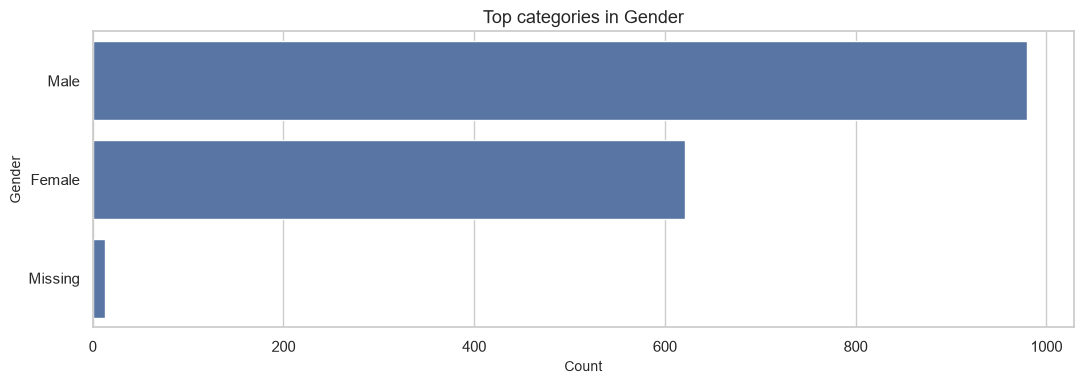


Column: Married
Data type: str
Missing values: 3
Missing percentage: 0.19
Unique values: 2


,Frequency
Married,
Yes,925
No,686
Missing,3


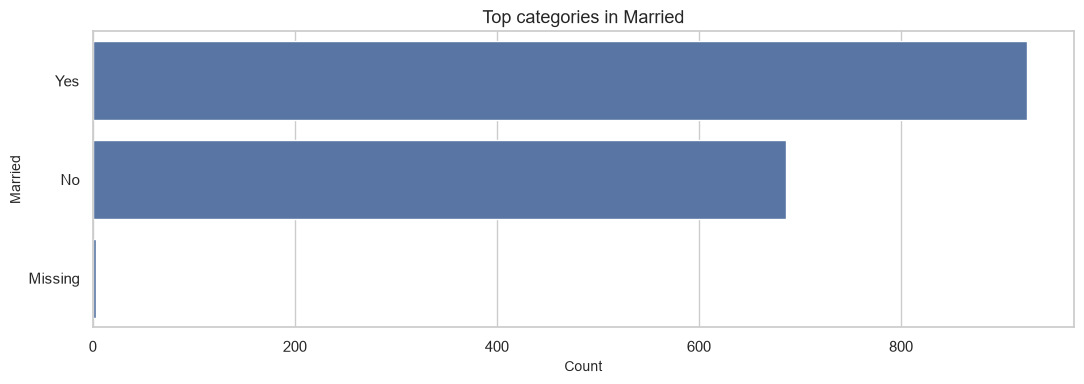


Column: Dependents
Data type: str
Missing values: 15
Missing percentage: 0.93
Unique values: 4


,Frequency
Dependents,
0,619
1,341
2,336
3+,303
Missing,15


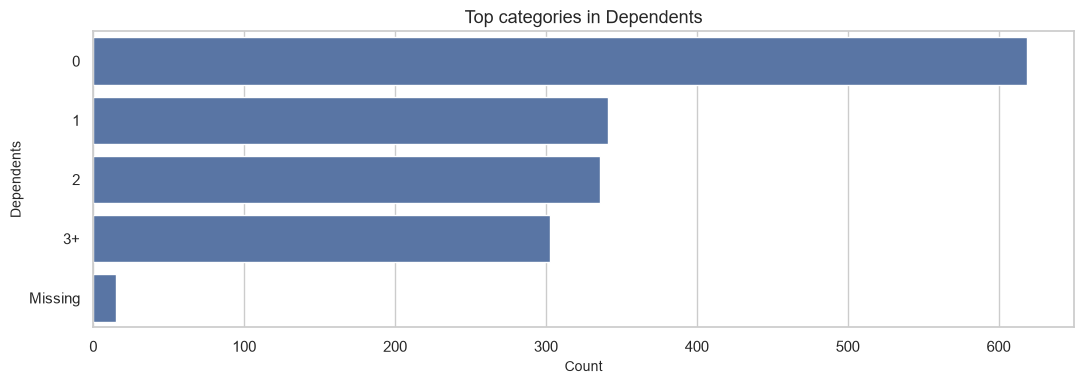


Column: Education
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Frequency
Education,
Graduate,952
Not Graduate,662


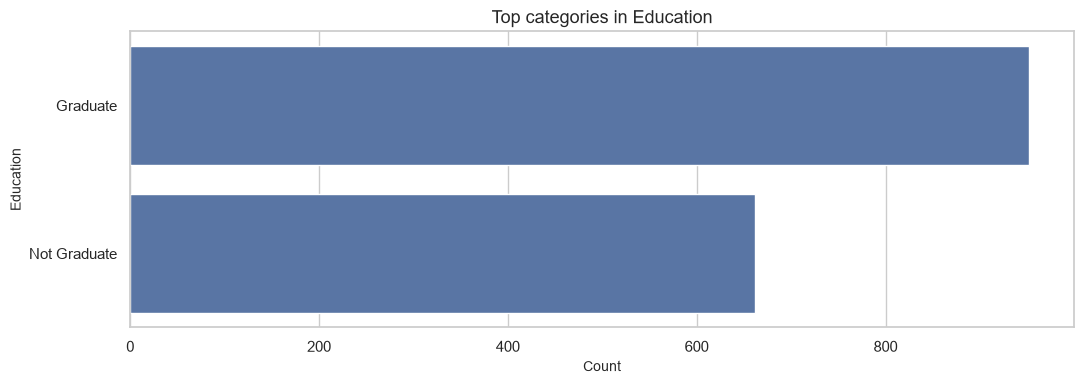


Column: Self_Employed
Data type: str
Missing values: 32
Missing percentage: 1.98
Unique values: 2


,Frequency
Self_Employed,
No,999
Yes,583
Missing,32


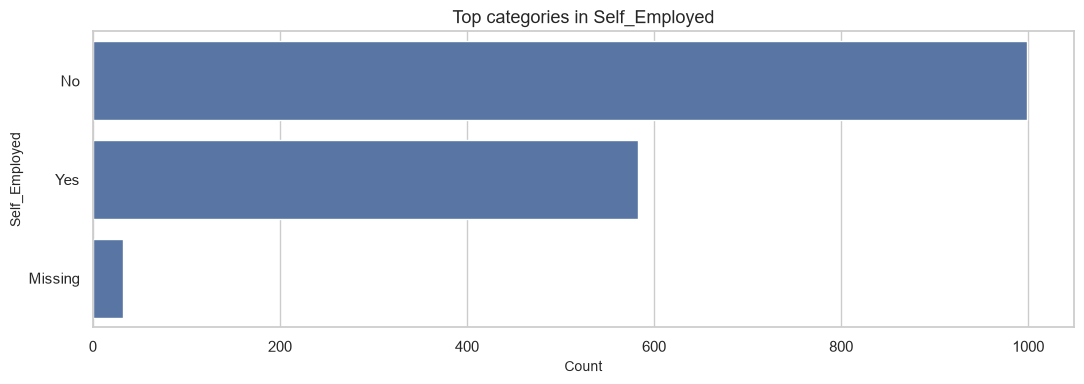


Column: ApplicantIncome
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 1455


,Summary
count,"1,614.00"
mean,"8,746.30"
std,"6,249.89"
min,150.00
25%,"3,675.25"
50%,"7,045.00"
75%,"13,251.00"
max,"81,000.00"


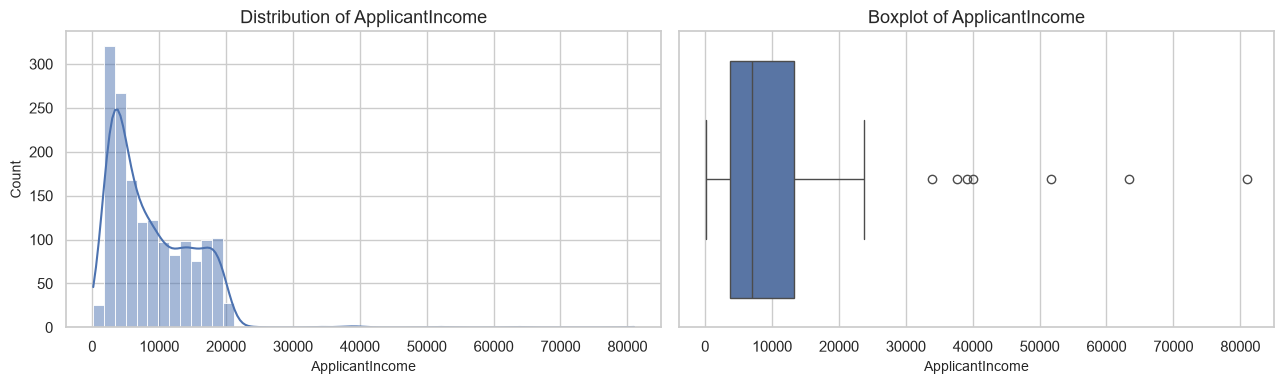


Column: CoapplicantIncome
Data type: float64
Missing values: 0
Missing percentage: 0.0
Unique values: 1206


,Summary
count,"1,614.00"
mean,"3,658.72"
std,"3,291.75"
min,0.00
25%,986.25
50%,"2,941.50"
75%,"5,893.00"
max,"41,667.00"


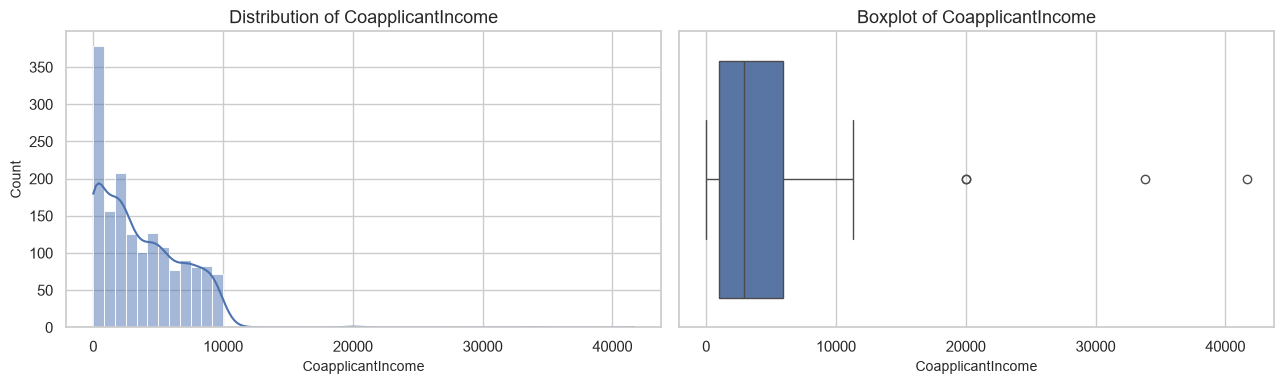


Column: LoanAmount
Data type: float64
Missing values: 22
Missing percentage: 1.36
Unique values: 461


,Summary
count,"1,592.00"
mean,218.85
std,133.62
min,9.00
25%,112.00
50%,180.00
75%,324.00
max,700.00


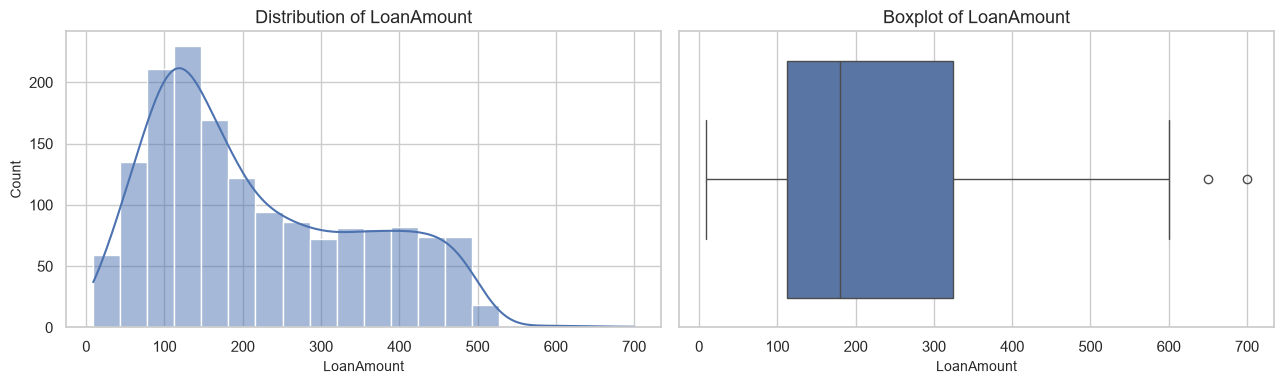


Column: Loan_Amount_Term
Data type: float64
Missing values: 14
Missing percentage: 0.87
Unique values: 10


,Summary
count,"1,600.00"
mean,290.48
std,81.90
min,12.00
25%,240.00
50%,360.00
75%,360.00
max,480.00


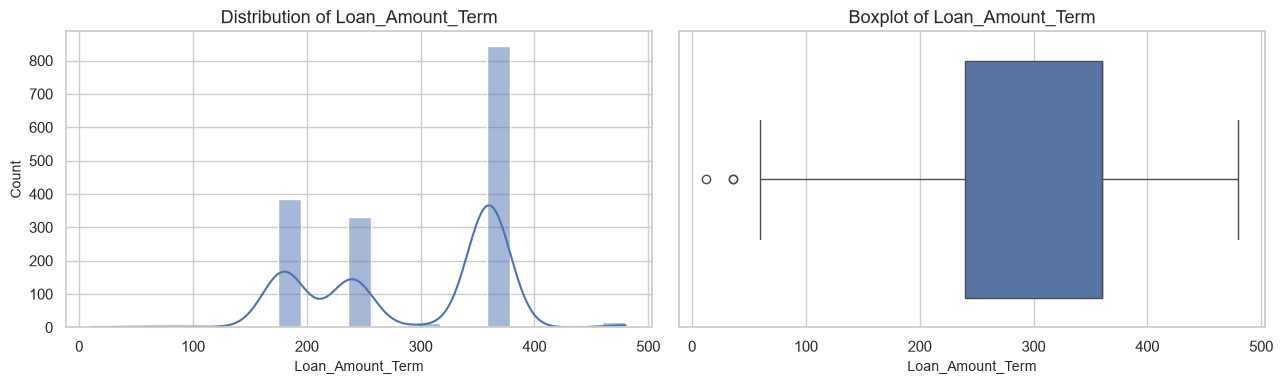


Column: Credit_History
Data type: float64
Missing values: 50
Missing percentage: 3.1
Unique values: 2


,Summary
count,"1,564.00"
mean,0.64
std,0.48
min,0.00
25%,0.00
50%,1.00
75%,1.00
max,1.00


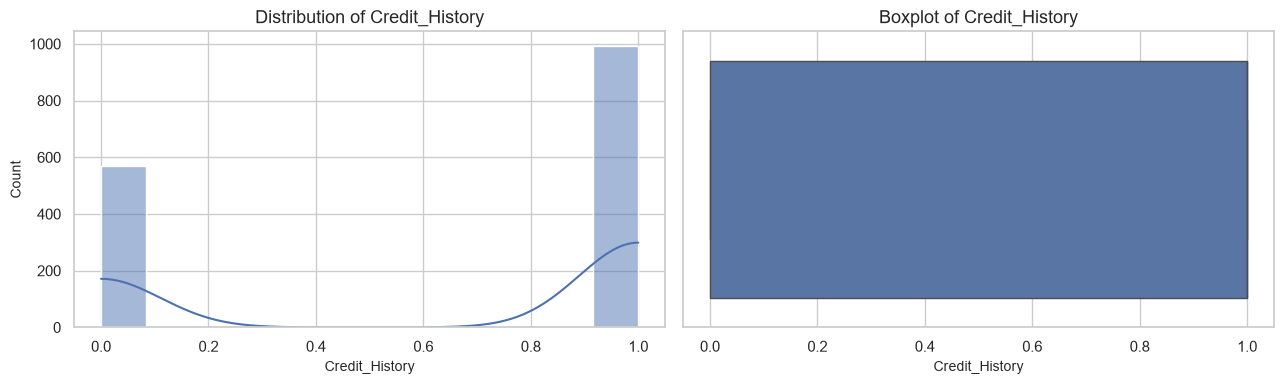


Column: Property_Area
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 3


,Frequency
Property_Area,
Urban,549
Semiurban,545
Rural,520


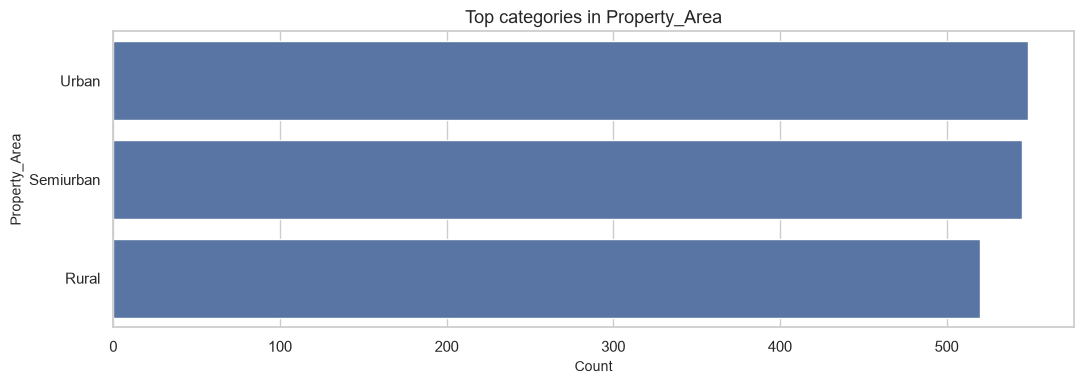


Column: Loan_Status
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Frequency
Loan_Status,
Y,915
N,699


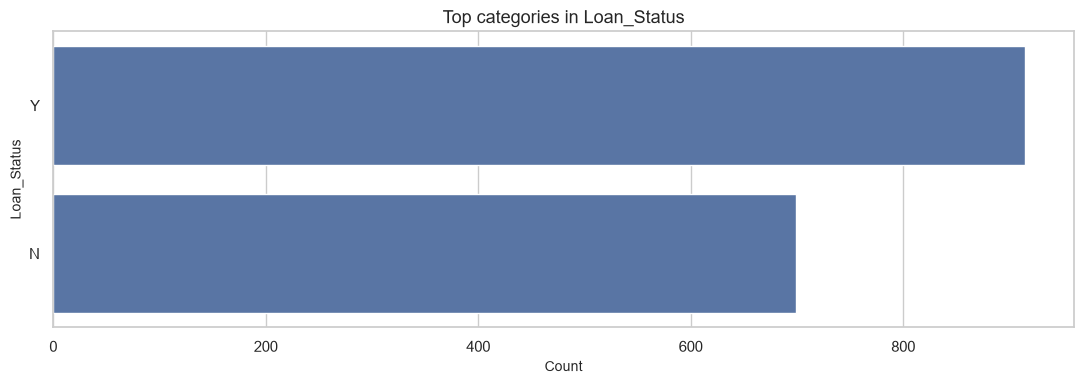

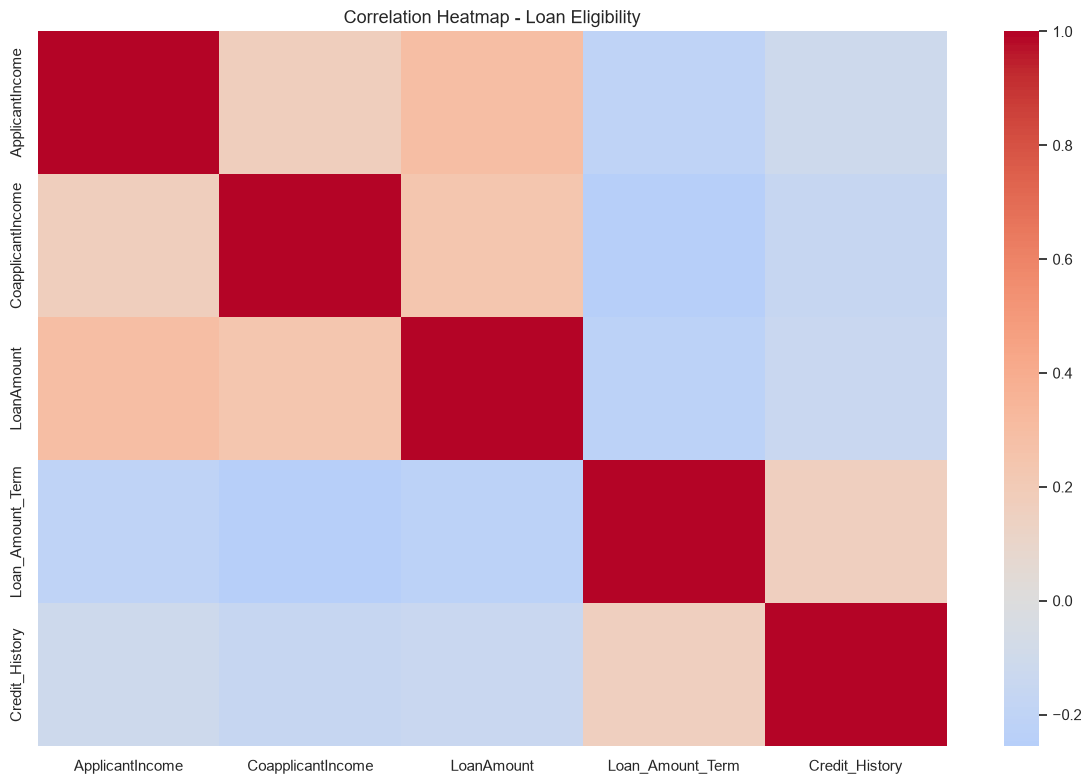

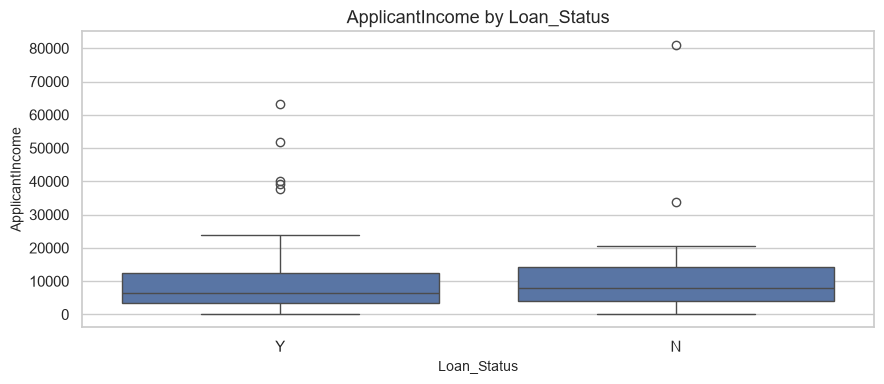

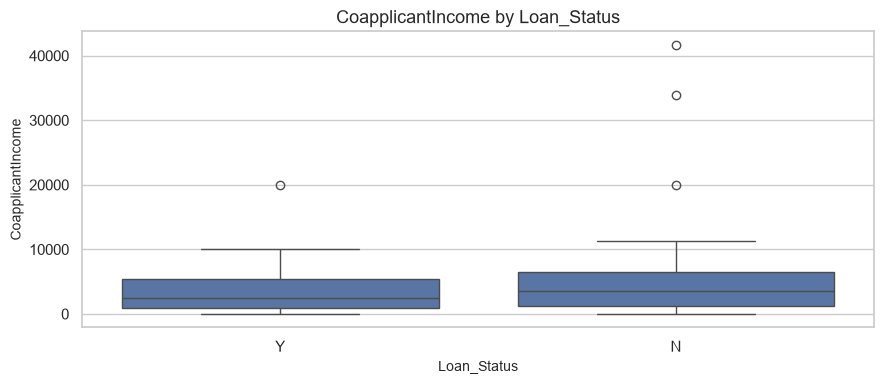

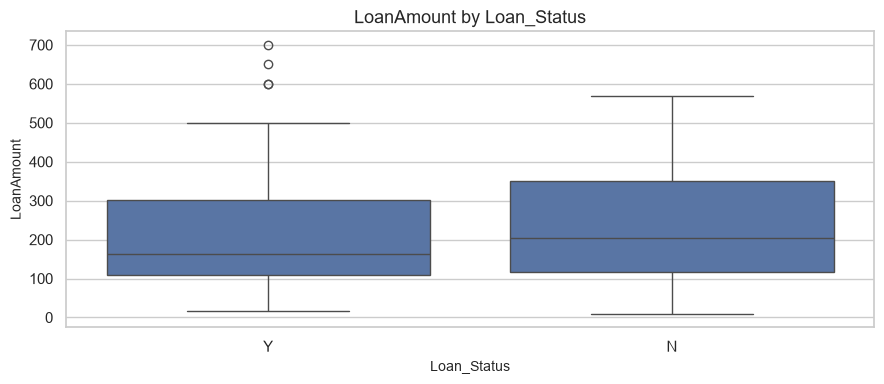

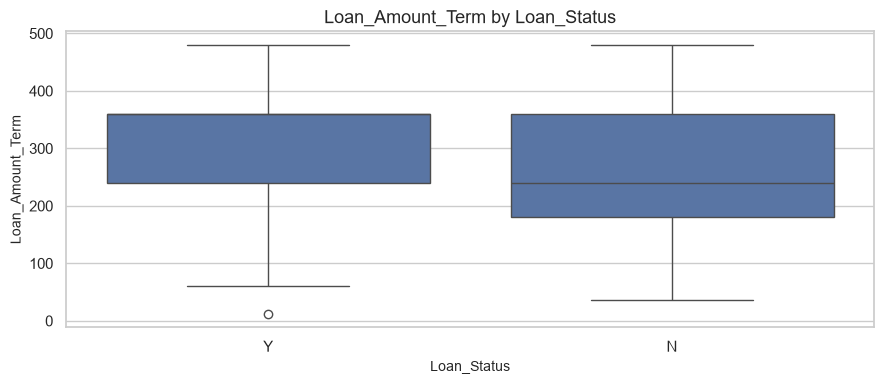

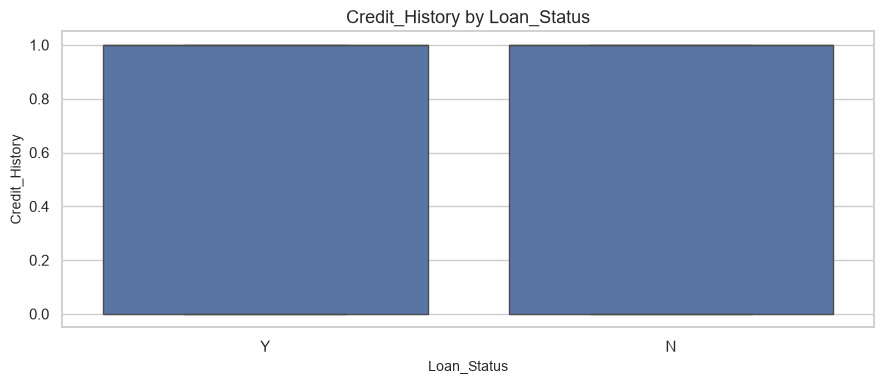

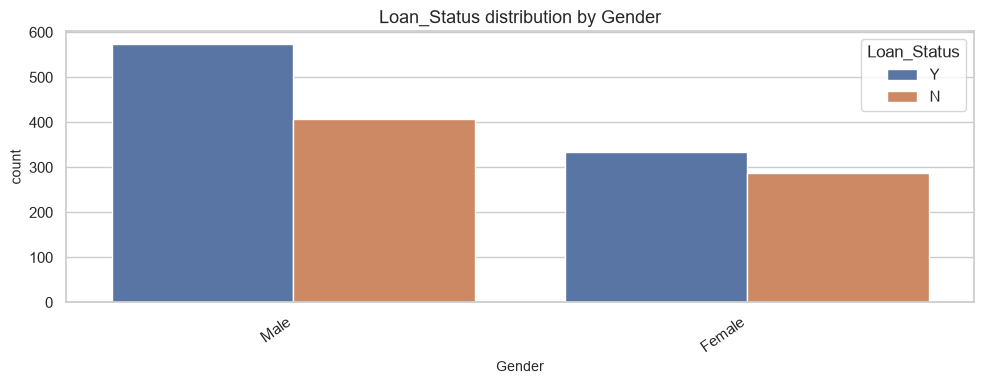

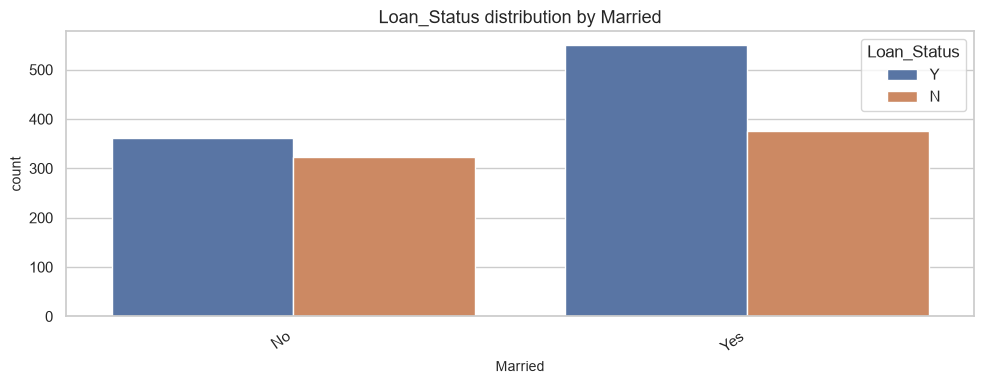

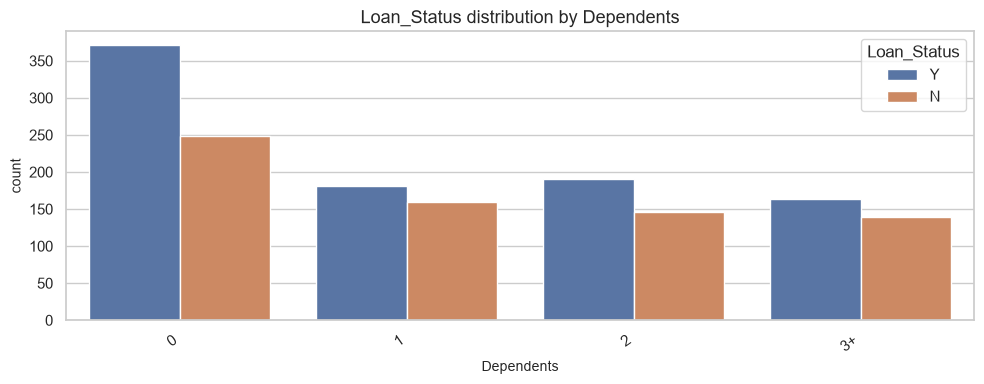

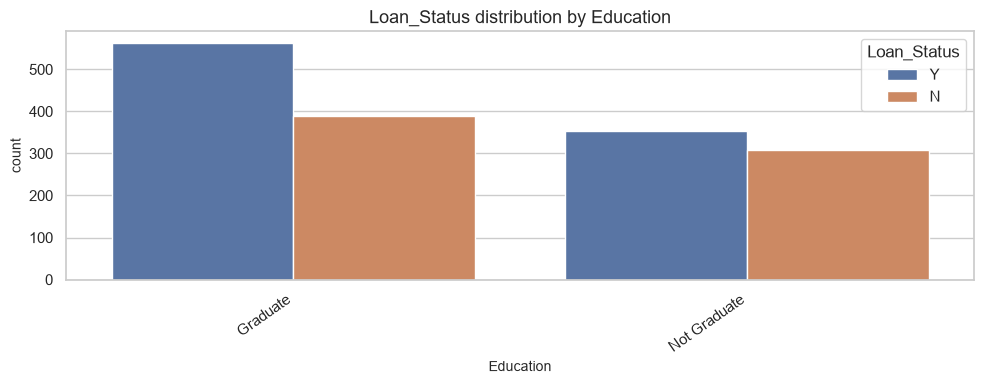

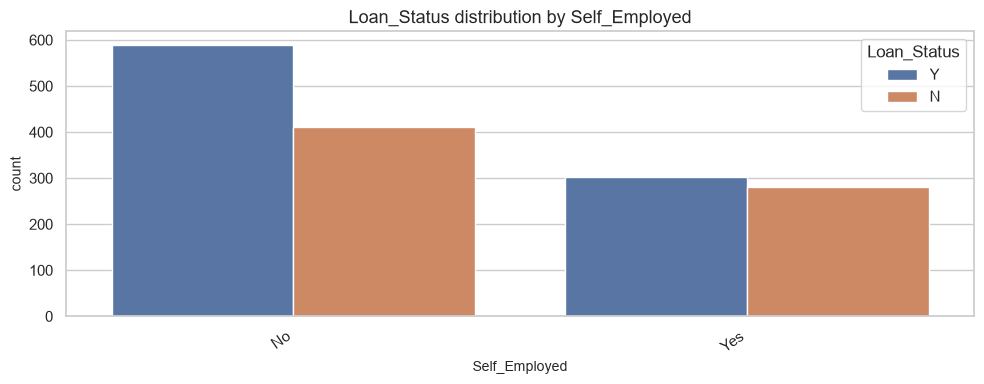

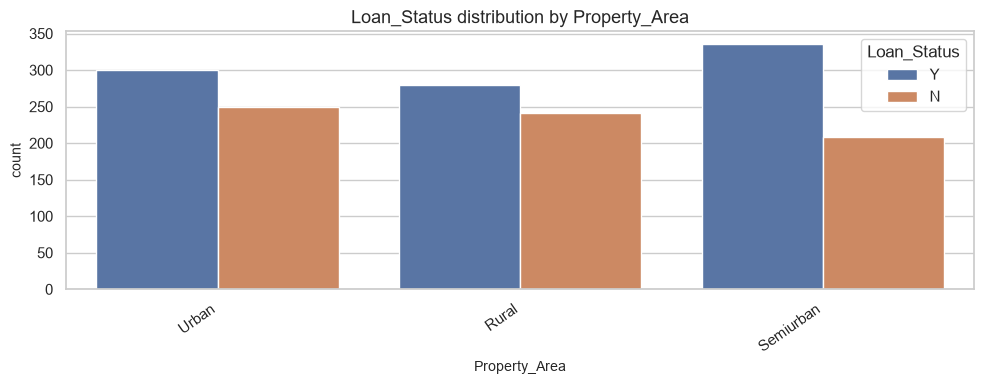

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,ApplicantIncome,"-10,688.38","27,614.62",7,0.43
1,CoapplicantIncome,"-6,373.88","13,253.12",4,0.25
2,LoanAmount,-206.00,642.00,2,0.13
3,Loan_Amount_Term,60.00,540.00,3,0.19
4,Credit_History,-1.50,2.50,0,0.00


Cleaning summary: Loan Eligibility
Duplicate rows removed: 0
Identifier columns excluded: ['Loan_ID']
Remaining missing values: 0
Final shape: (1614, 12)

Missing values after cleaning:


,Missing Values
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0



Data types after cleaning:


,Data Type
Gender,str
Married,str
Dependents,str
Education,str
Self_Employed,str
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64
Credit_History,float64


Loan dataset final verification
Shape: (1614, 12)
Missing values: 0
Duplicate rows: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.00,180.00,360.00,1.00,Urban,Y
1,Male,Yes,1,Graduate,No,4583,"1,508.00",128.00,360.00,1.00,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.00,66.00,360.00,1.00,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,"2,358.00",120.00,360.00,1.00,Urban,Y
4,Male,No,0,Graduate,No,6000,0.00,141.00,360.00,1.00,Urban,Y


In [3]:
loan_raw = load_dataset(["loan-train(1).csv", "loan-train.csv"])
loan_report = inspect_dataset(loan_raw, "Loan Eligibility")
analyze_columns(loan_raw, "Loan Eligibility", identifier_columns=["Loan_ID"])
analyze_relationships(loan_raw, "Loan Eligibility", target_column="Loan_Status")
loan_outliers = outlier_summary(loan_raw)
loan_cleaned = clean_dataset(
    loan_raw,
    "Loan Eligibility",
    identifier_columns=["Loan_ID"]
)
print("Loan dataset final verification")
print("Shape:", loan_cleaned.shape)
print("Missing values:", loan_cleaned.isna().sum().sum())
print("Duplicate rows:", loan_cleaned.duplicated().sum())
display(loan_cleaned.head())


### Loan Eligibility: observations

Review the generated tables and plots to identify which applicant characteristics are associated with loan approval. Pay particular attention to credit history, applicant income, co-applicant income, loan amount and property area. The notebook retains statistical outliers rather than removing them automatically, because unusual financial values may be valid observations.

The `Loan_ID` field is excluded from the cleaned analytical table because it identifies records rather than describing applicant characteristics.


# Dataset 2: Adult Census Income

This dataset contains demographic, employment, education and financial information. The target column is `income`. The analysis examines each feature and its relationship with the income category.


Loaded file: adult.csv
DATASET: Adult Census Income
Shape: (48842, 15)
Number of rows: 48842
Number of columns: 15

First five rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"48,842.00",NaN,NaN,NaN,38.64,13.71,17.00,28.00,37.00,48.00,90.00
workclass,48842,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,"48,842.00",NaN,NaN,NaN,"189,664.13","105,604.03","12,285.00","117,550.50","178,144.50","237,642.00","1,490,400.00"
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educational-num,"48,842.00",NaN,NaN,NaN,10.08,2.57,1.00,9.00,10.00,12.00,16.00
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,48842,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Duplicate rows: 52

Column-wise quality report:


,Data Type,Missing Values,Missing Percentage,Unique Values
age,int64,0,0.00,74
workclass,str,0,0.00,9
fnlwgt,int64,0,0.00,28523
education,str,0,0.00,16
educational-num,int64,0,0.00,16
marital-status,str,0,0.00,7
occupation,str,0,0.00,15
relationship,str,0,0.00,6
race,str,0,0.00,5
gender,str,0,0.00,2


Column-by-column analysis: Adult Census Income

Column: age
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 74


,Summary
count,"48,842.00"
mean,38.64
std,13.71
min,17.00
25%,28.00
50%,37.00
75%,48.00
max,90.00


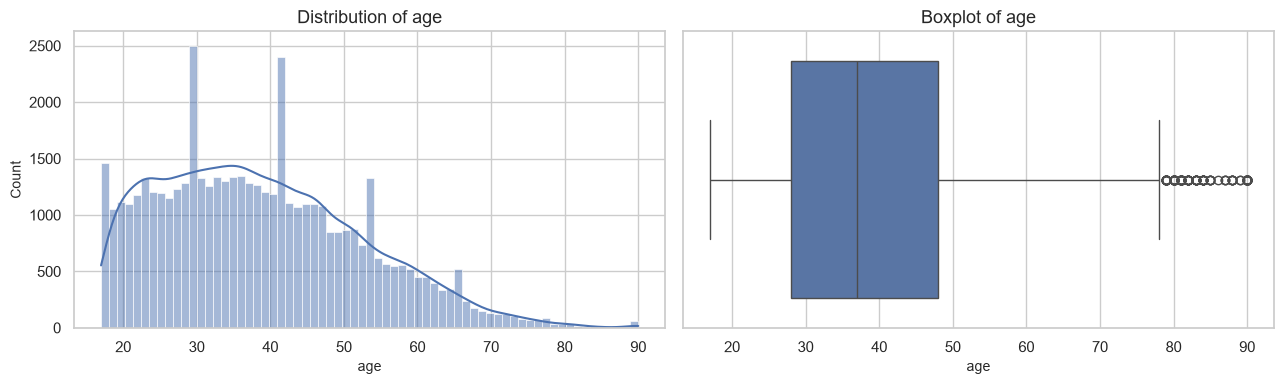


Column: workclass
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 9


,Frequency
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
?,2799
State-gov,1981
Self-emp-inc,1695
Federal-gov,1432
Without-pay,21
Never-worked,10


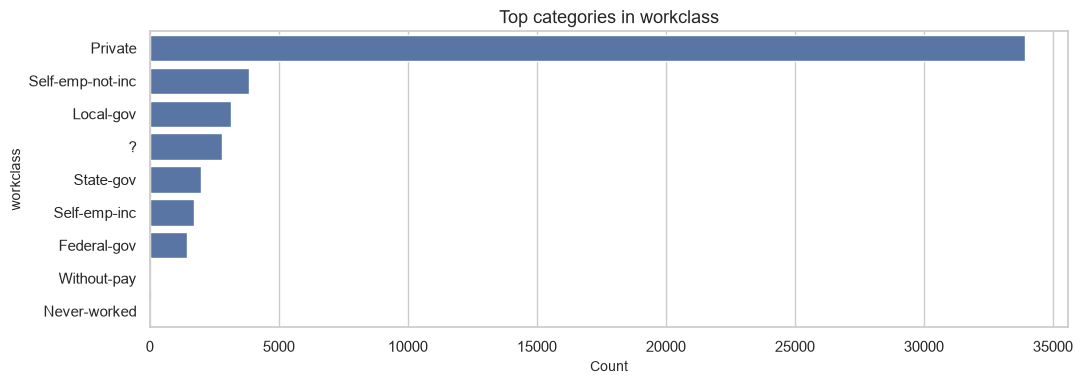


Column: fnlwgt
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 28523


,Summary
count,"48,842.00"
mean,"189,664.13"
std,"105,604.03"
min,"12,285.00"
25%,"117,550.50"
50%,"178,144.50"
75%,"237,642.00"
max,"1,490,400.00"


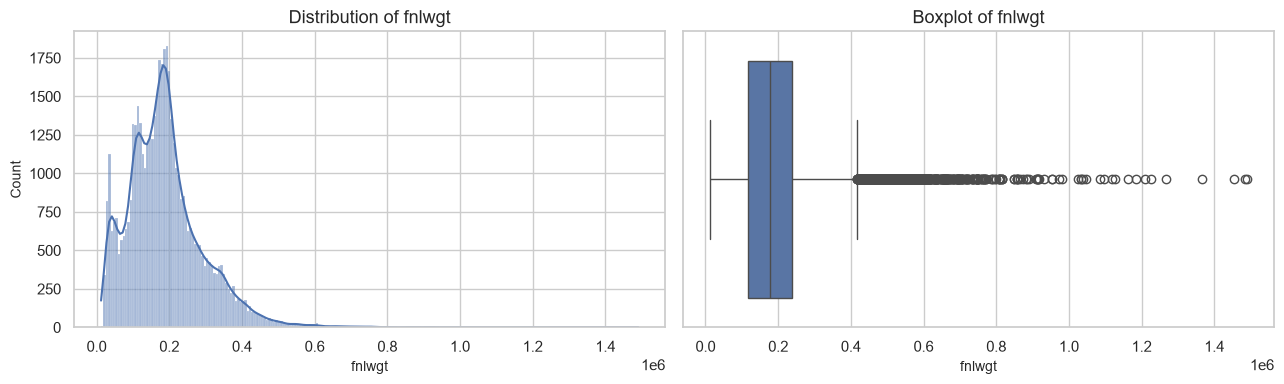


Column: education
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 16


,Frequency
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955


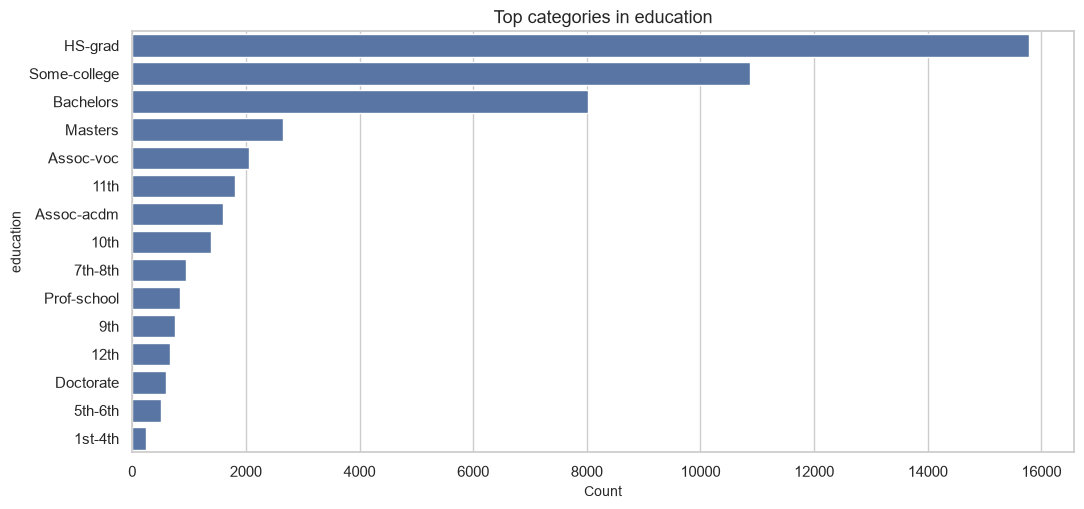


Column: educational-num
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 16


,Summary
count,"48,842.00"
mean,10.08
std,2.57
min,1.00
25%,9.00
50%,10.00
75%,12.00
max,16.00


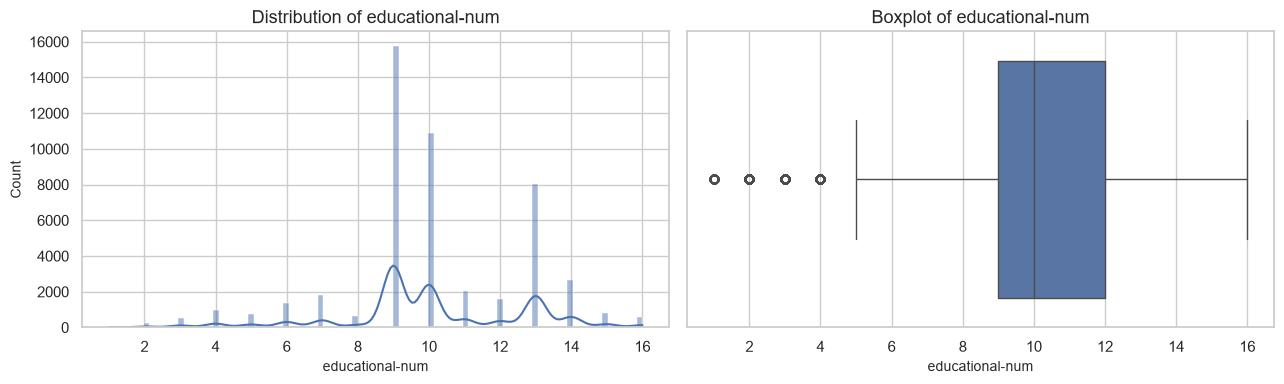


Column: marital-status
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 7


,Frequency
marital-status,
Married-civ-spouse,22379
Never-married,16117
Divorced,6633
Separated,1530
Widowed,1518
Married-spouse-absent,628
Married-AF-spouse,37


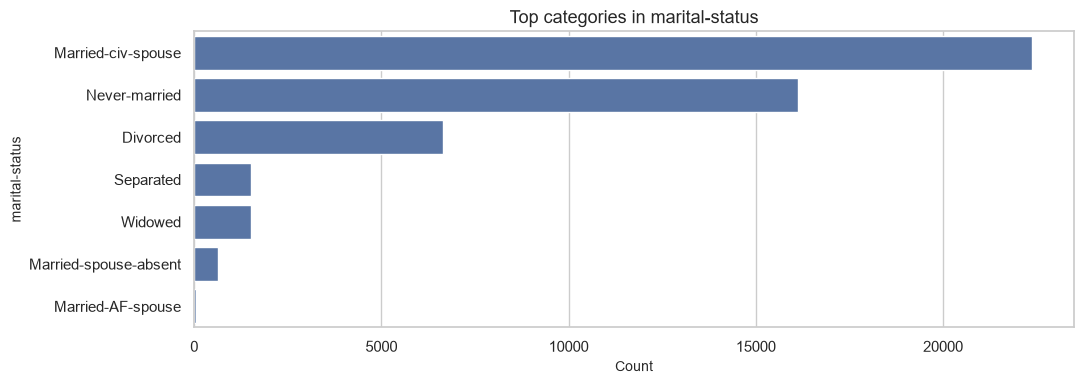


Column: occupation
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 15


,Frequency
occupation,
Prof-specialty,6172
Craft-repair,6112
Exec-managerial,6086
Adm-clerical,5611
Sales,5504
Other-service,4923
Machine-op-inspct,3022
?,2809
Transport-moving,2355


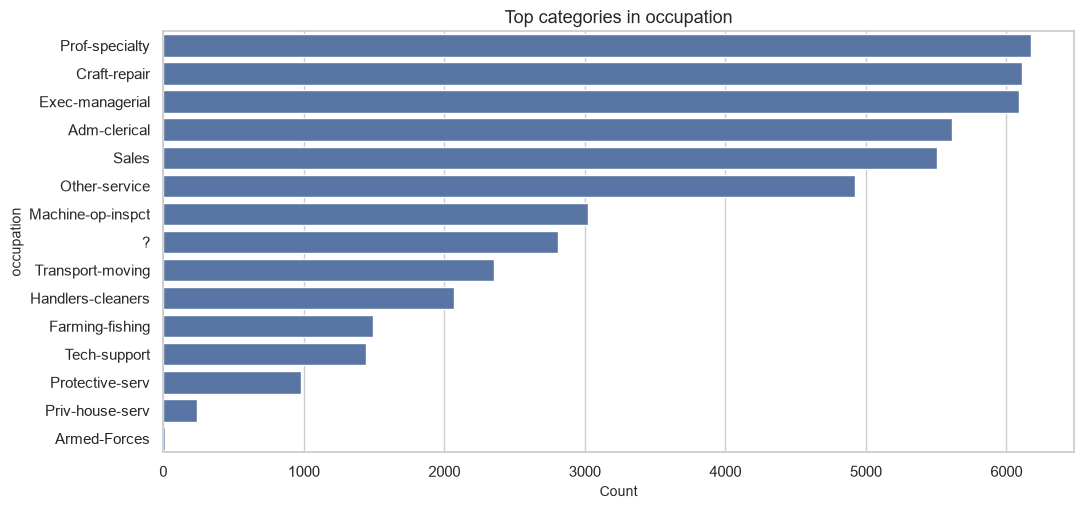


Column: relationship
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 6


,Frequency
relationship,
Husband,19716
Not-in-family,12583
Own-child,7581
Unmarried,5125
Wife,2331
Other-relative,1506


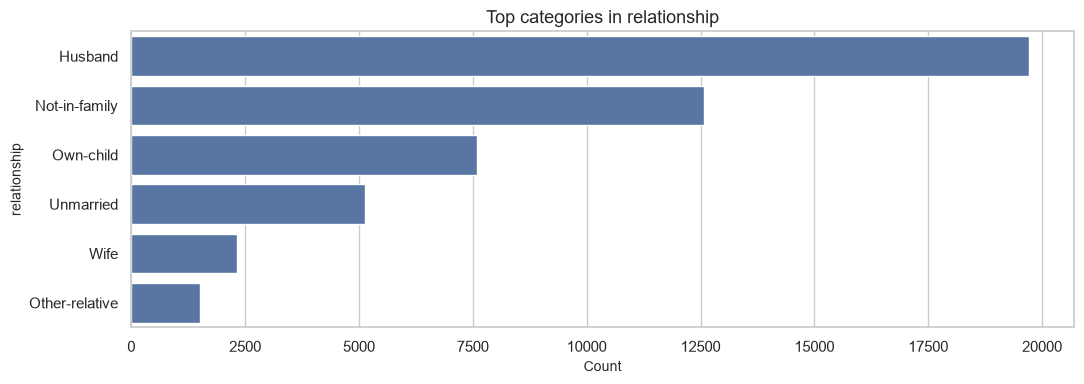


Column: race
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 5


,Frequency
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
Amer-Indian-Eskimo,470
Other,406


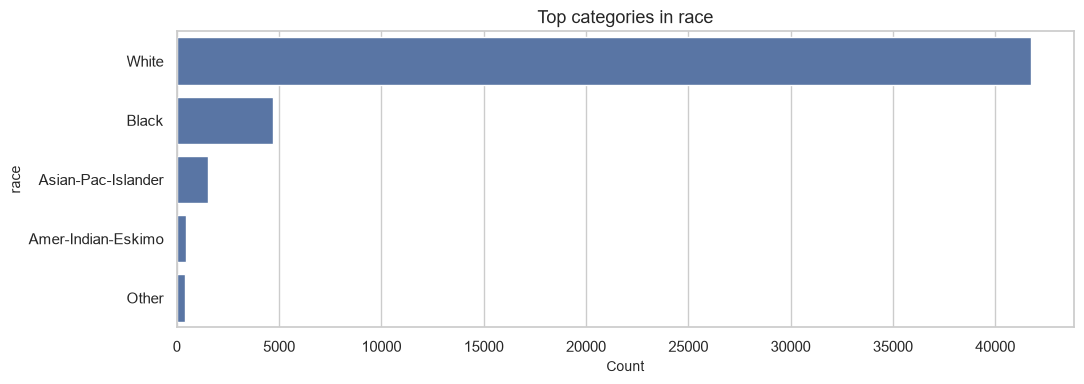


Column: gender
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Frequency
gender,
Male,32650
Female,16192


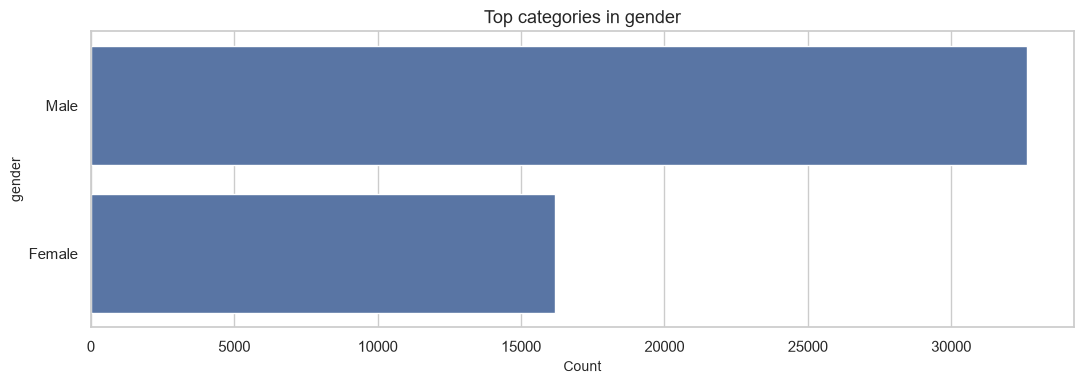


Column: capital-gain
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 123


,Summary
count,"48,842.00"
mean,"1,079.07"
std,"7,452.02"
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,"99,999.00"


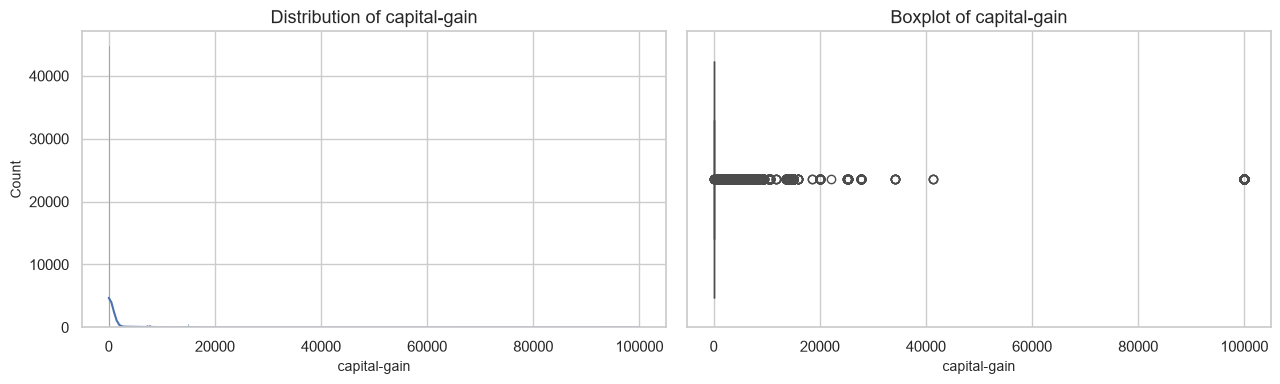


Column: capital-loss
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 99


,Summary
count,"48,842.00"
mean,87.50
std,403.00
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,"4,356.00"


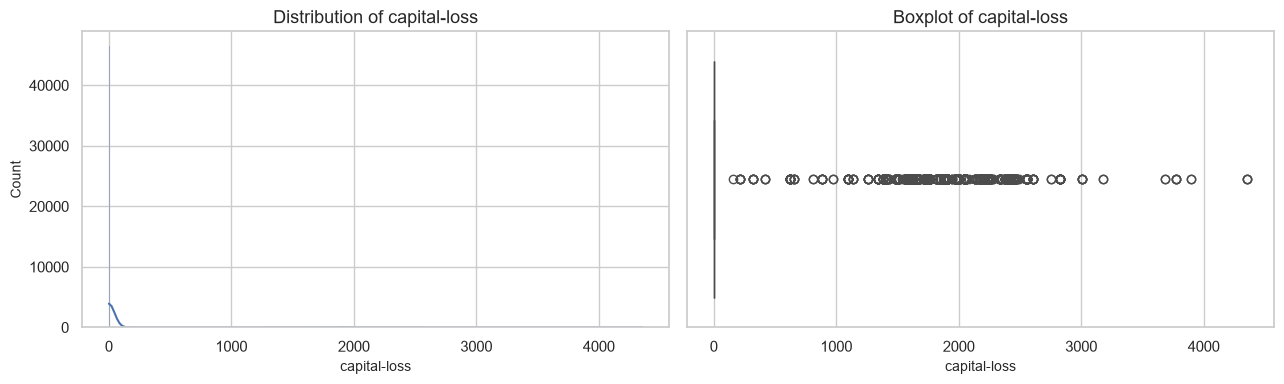


Column: hours-per-week
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 96


,Summary
count,"48,842.00"
mean,40.42
std,12.39
min,1.00
25%,40.00
50%,40.00
75%,45.00
max,99.00


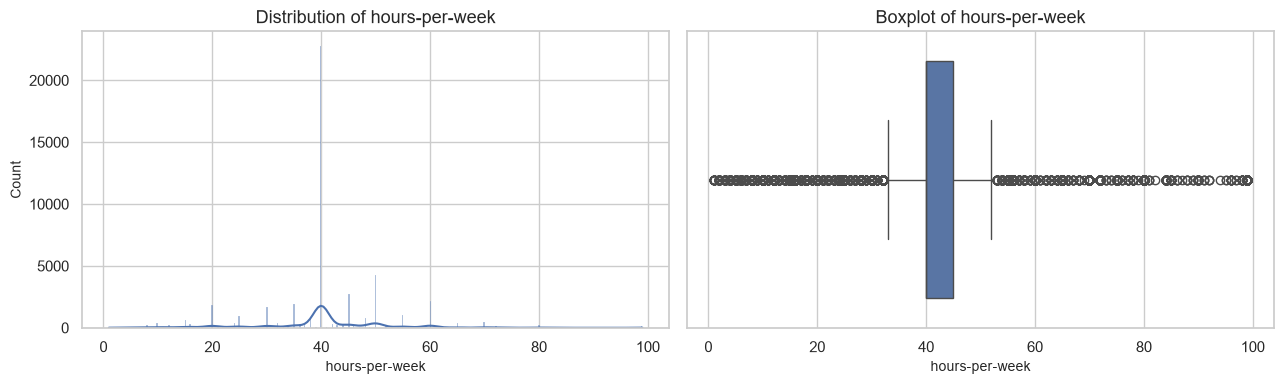


Column: native-country
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 42


,Frequency
native-country,
United-States,43832
Mexico,951
?,857
Philippines,295
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151


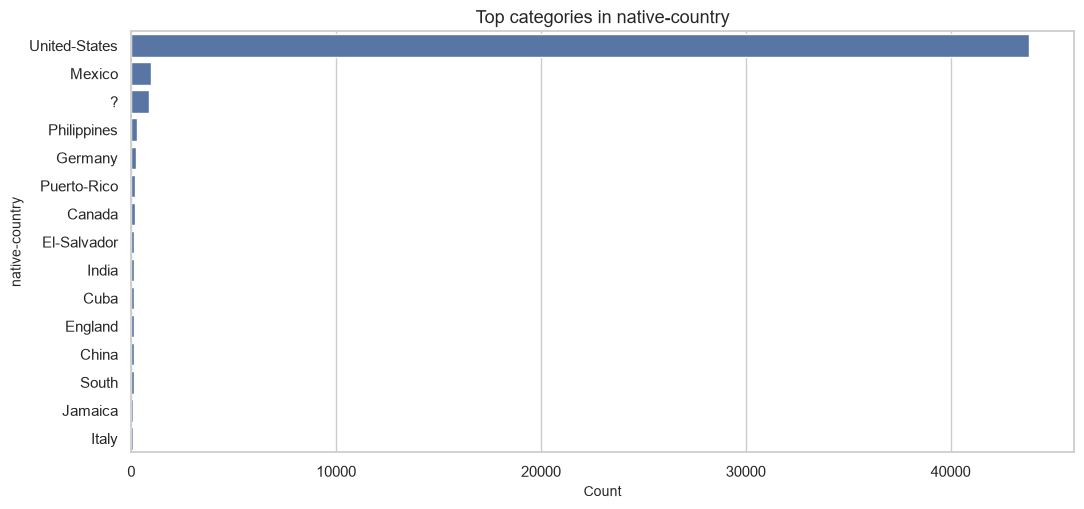


Column: income
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Frequency
income,
<=50K,37155
>50K,11687


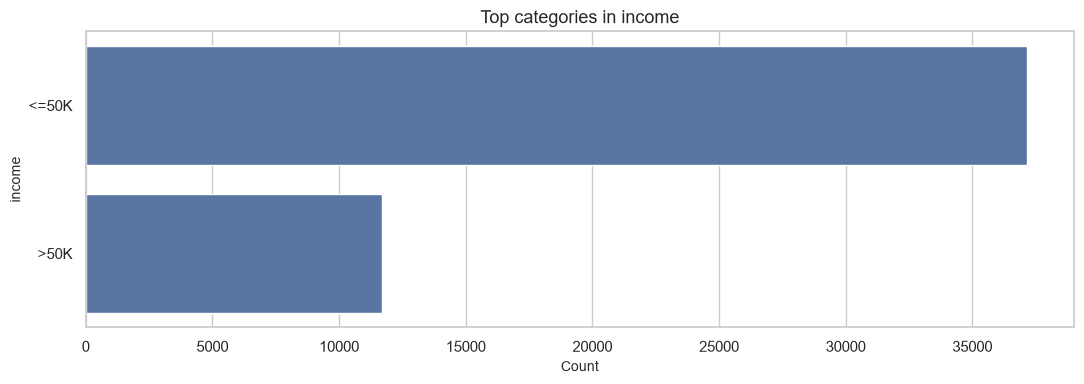

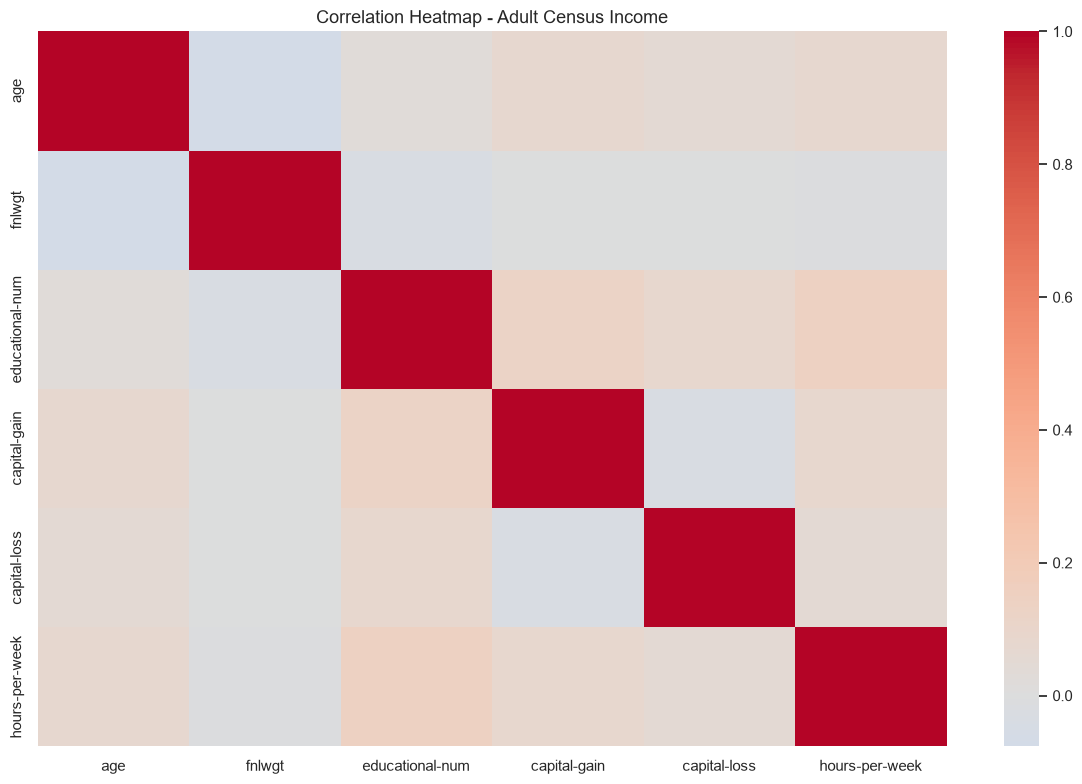

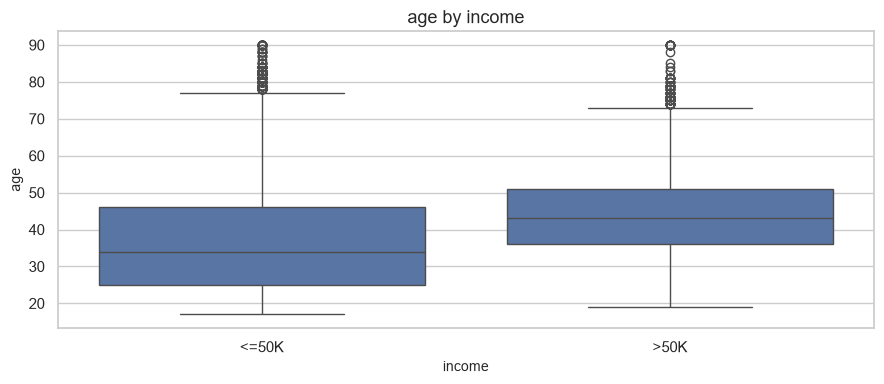

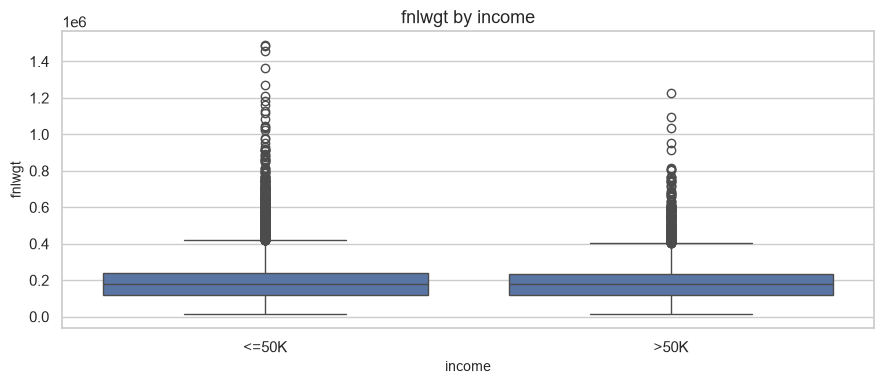

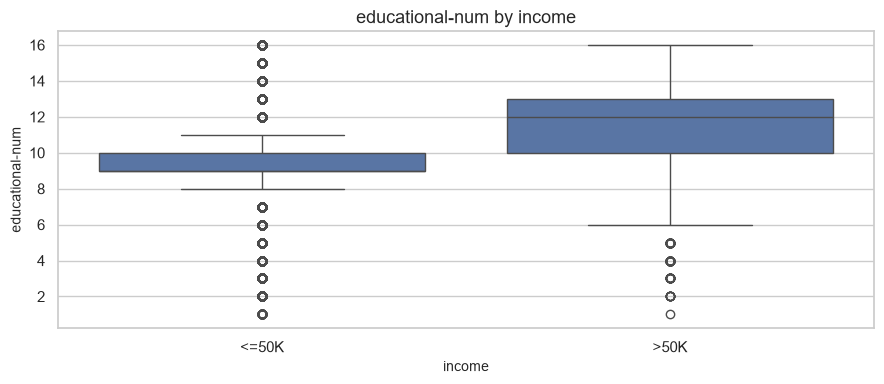

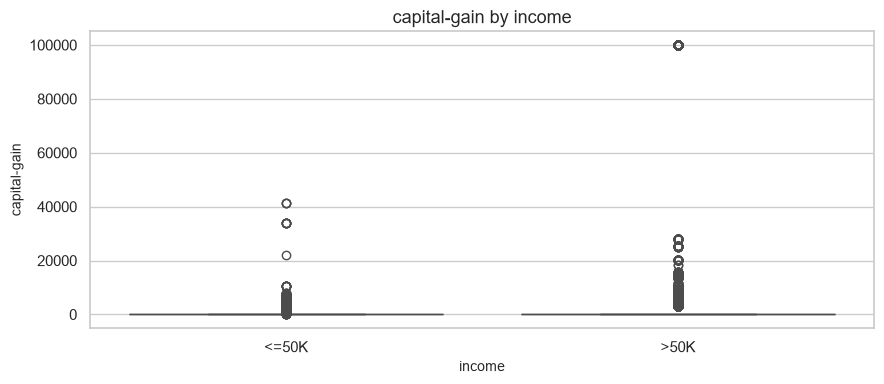

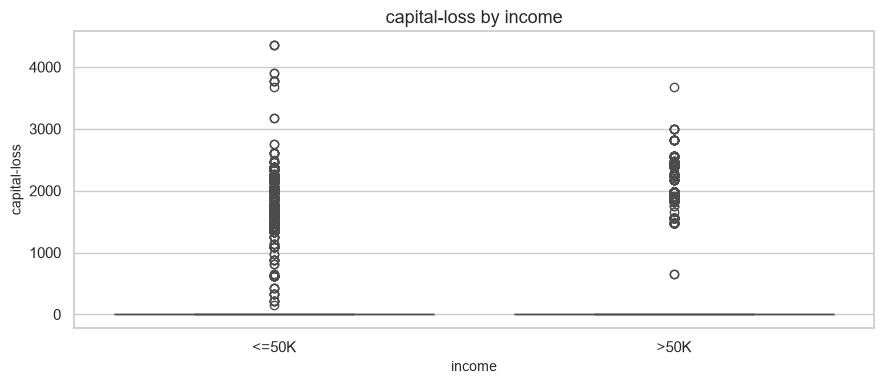

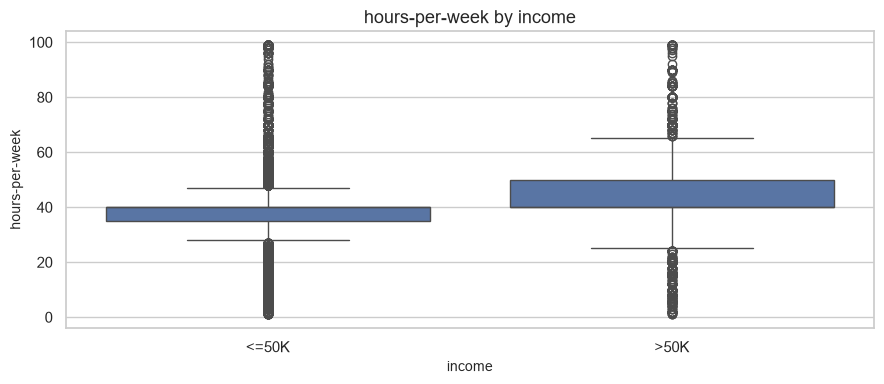

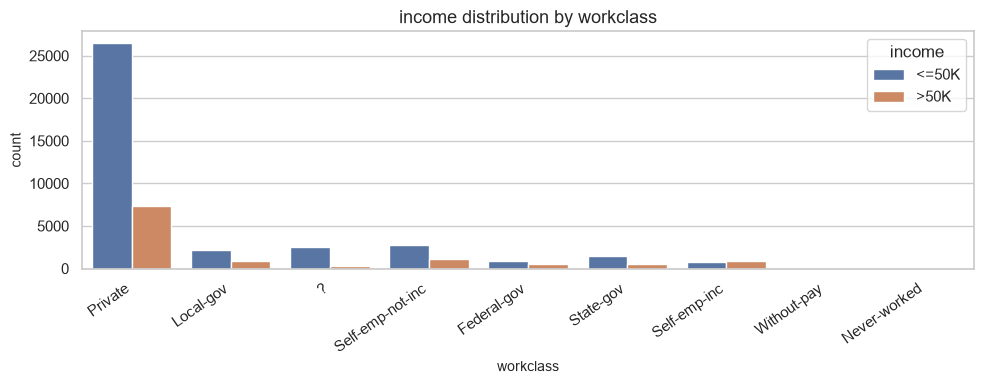

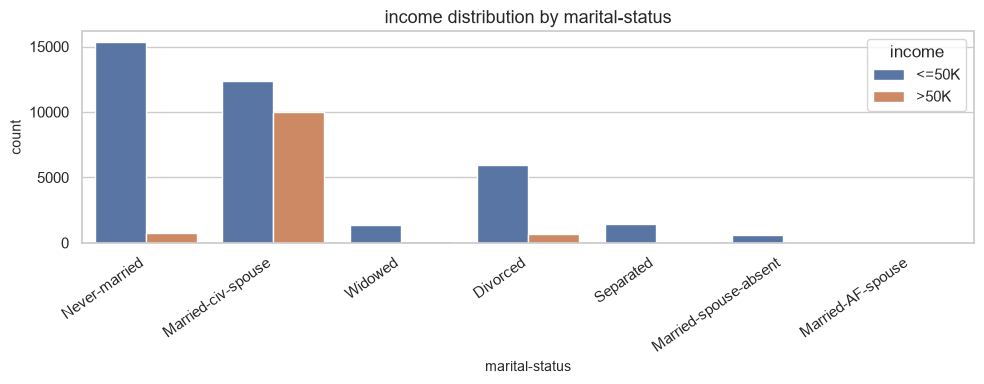

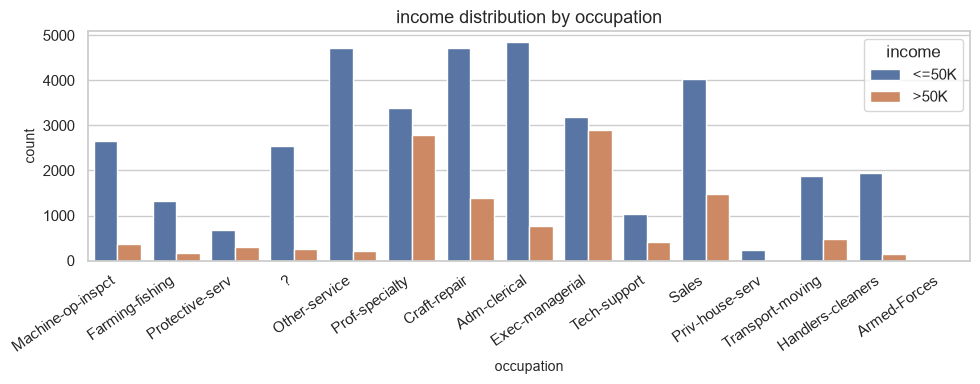

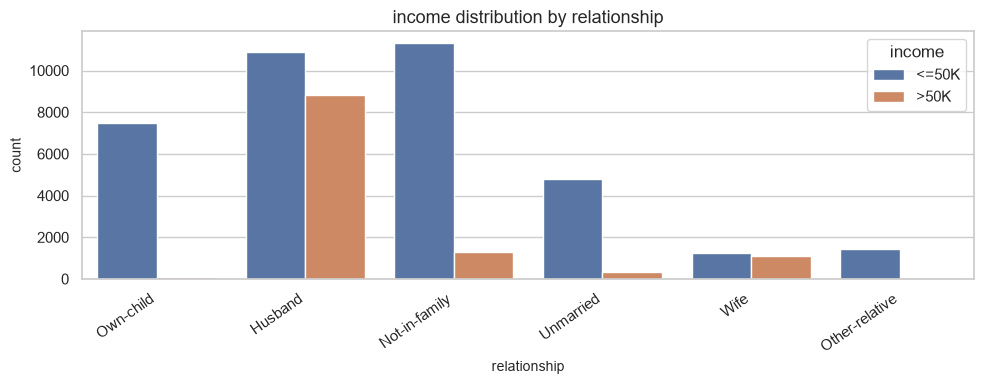

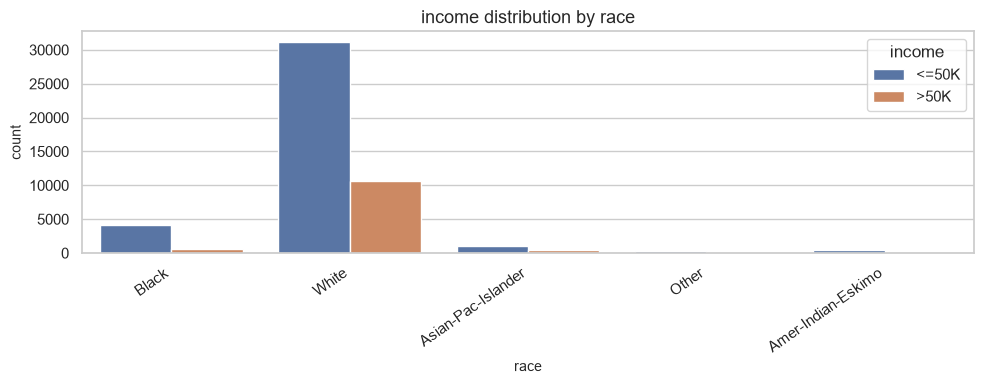

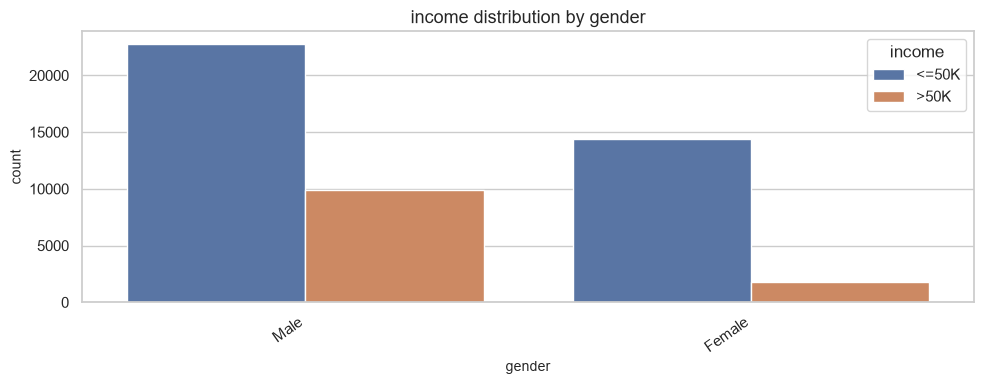

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,-2.00,78.00,216,0.44
1,fnlwgt,"-62,586.75","417,779.25",1453,2.97
2,educational-num,4.50,16.50,1794,3.67
3,capital-gain,0.00,0.00,4035,8.26
4,capital-loss,0.00,0.00,2282,4.67
5,hours-per-week,32.50,52.50,13496,27.63


Cleaning summary: Adult Census Income
Duplicate rows removed: 52
Identifier columns excluded: []
Remaining missing values: 0
Final shape: (48790, 15)

Missing values after cleaning:


,Missing Values
age,0
workclass,0
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0



Data types after cleaning:


,Data Type
age,int64
workclass,str
fnlwgt,int64
education,str
educational-num,int64
marital-status,str
occupation,str
relationship,str
race,str
gender,str


Adult dataset final verification
Shape: (48790, 15)
Missing values: 0
Duplicate rows: 1


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,103497,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K


In [4]:
adult_raw = load_dataset(["adult.csv", "adult.data"])
adult_report = inspect_dataset(adult_raw, "Adult Census Income")
analyze_columns(adult_raw, "Adult Census Income")
analyze_relationships(adult_raw, "Adult Census Income", target_column="income")
adult_outliers = outlier_summary(adult_raw)
adult_cleaned = clean_dataset(
    adult_raw,
    "Adult Census Income"
)
print("Adult dataset final verification")
print("Shape:", adult_cleaned.shape)
print("Missing values:", adult_cleaned.isna().sum().sum())
print("Duplicate rows:", adult_cleaned.duplicated().sum())
display(adult_cleaned.head())


### Adult Census Income: observations

Use the generated frequency tables and plots to compare income categories across education, occupation, workclass, marital status, age and hours worked per week. Numerical distributions and the correlation heatmap help identify patterns among numerical features. The `fnlwgt` column is a census sampling weight and should be interpreted differently from a direct measure of income or wealth.


# Dataset 3: Hotel Booking

The hotel booking dataset contains reservation details, guest information, booking channels, stay duration, prices and reservation outcomes. The analysis checks all columns. Direct personal identifiers are summarized without displaying their individual values and are excluded from the cleaned analytical table.


Loaded file: hotel_booking.csv
DATASET: Hotel Booking
Shape: (119390, 36)
Number of rows: 119390
Number of columns: 36

First five rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,"119,390.00",NaN,NaN,NaN,0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,"119,390.00",NaN,NaN,NaN,104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,"119,390.00",NaN,NaN,NaN,"2,016.16",0.71,"2,015.00","2,016.00","2,016.00","2,017.00","2,017.00"
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,"119,390.00",NaN,NaN,NaN,27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,"119,390.00",NaN,NaN,NaN,15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,"119,390.00",NaN,NaN,NaN,0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,"119,390.00",NaN,NaN,NaN,2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,"119,390.00",NaN,NaN,NaN,1.86,0.58,0.00,2.00,2.00,2.00,55.00



Duplicate rows: 0

Column-wise quality report:


,Data Type,Missing Values,Missing Percentage,Unique Values
company,float64,112593,94.31,352
agent,float64,16340,13.69,333
country,str,488,0.41,177
hotel,str,0,0.00,2
arrival_date_year,int64,0,0.00,3
lead_time,int64,0,0.00,479
is_canceled,int64,0,0.00,2
arrival_date_month,str,0,0.00,12
stays_in_week_nights,int64,0,0.00,35
adults,int64,0,0.00,14


Column-by-column analysis: Hotel Booking

Column: hotel
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Frequency
hotel,
City Hotel,79330
Resort Hotel,40060


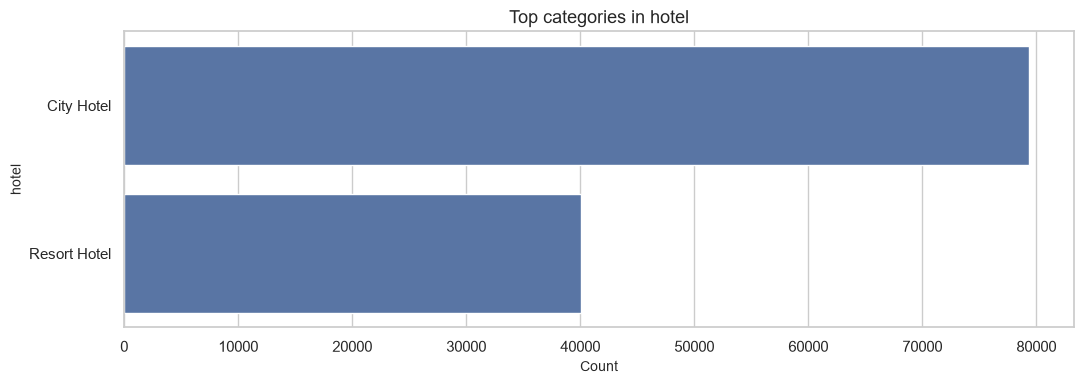


Column: is_canceled
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Summary
count,"119,390.00"
mean,0.37
std,0.48
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,1.00


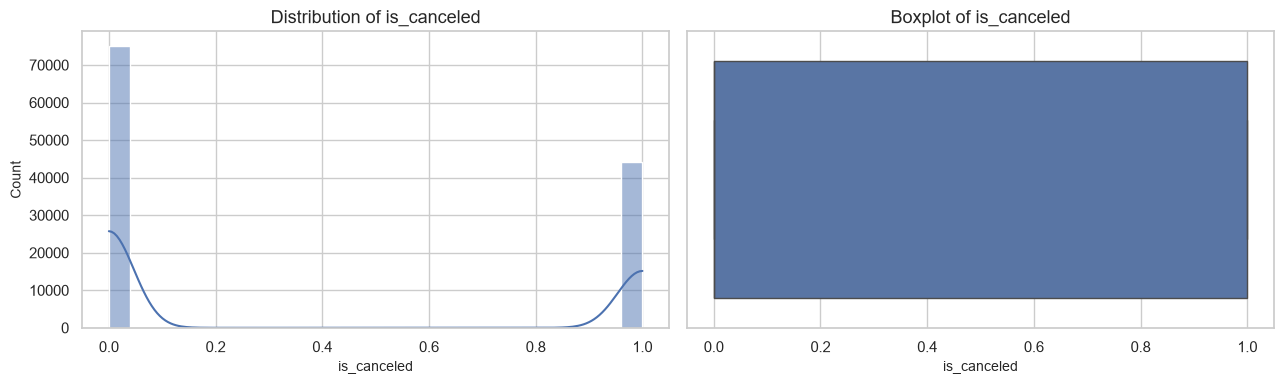


Column: lead_time
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 479


,Summary
count,"119,390.00"
mean,104.01
std,106.86
min,0.00
25%,18.00
50%,69.00
75%,160.00
max,737.00


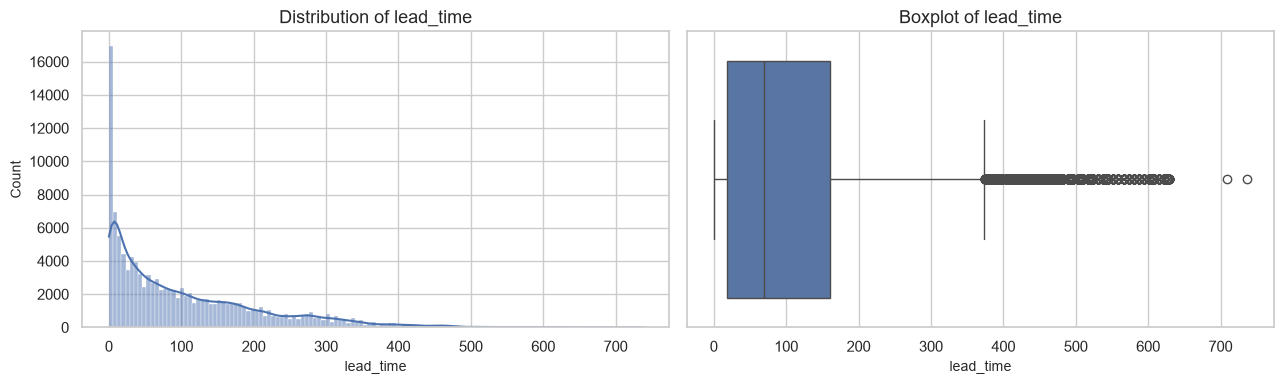


Column: arrival_date_year
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 3


,Summary
count,"119,390.00"
mean,"2,016.16"
std,0.71
min,"2,015.00"
25%,"2,016.00"
50%,"2,016.00"
75%,"2,017.00"
max,"2,017.00"


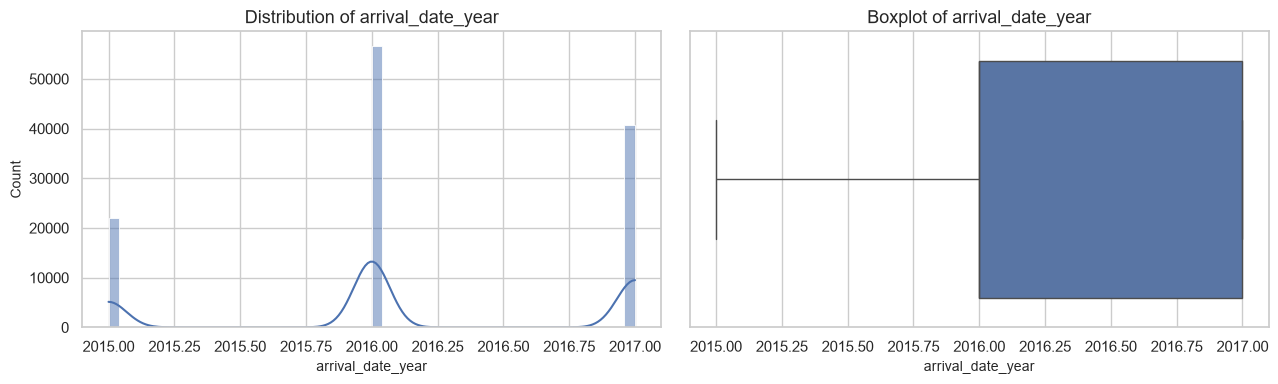


Column: arrival_date_month
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 12


,Frequency
arrival_date_month,
August,13877
July,12661
May,11791
October,11160
April,11089
June,10939
September,10508
March,9794
February,8068


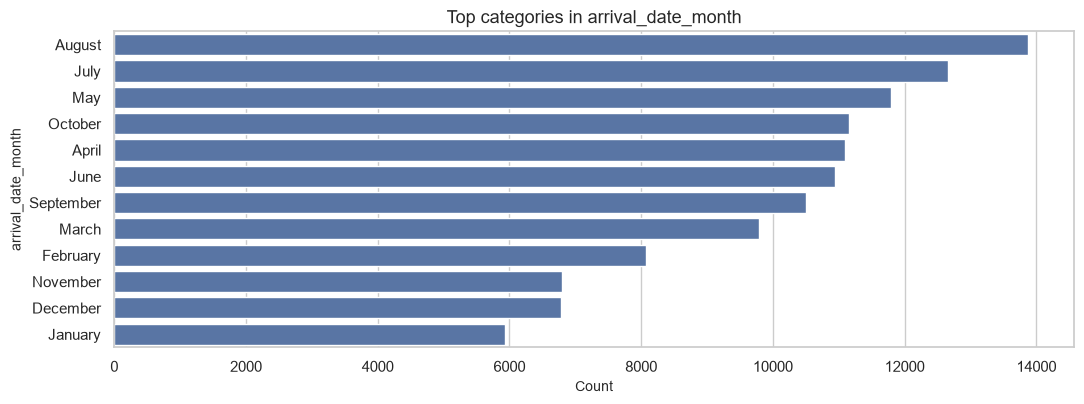


Column: arrival_date_week_number
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 53


,Summary
count,"119,390.00"
mean,27.17
std,13.61
min,1.00
25%,16.00
50%,28.00
75%,38.00
max,53.00


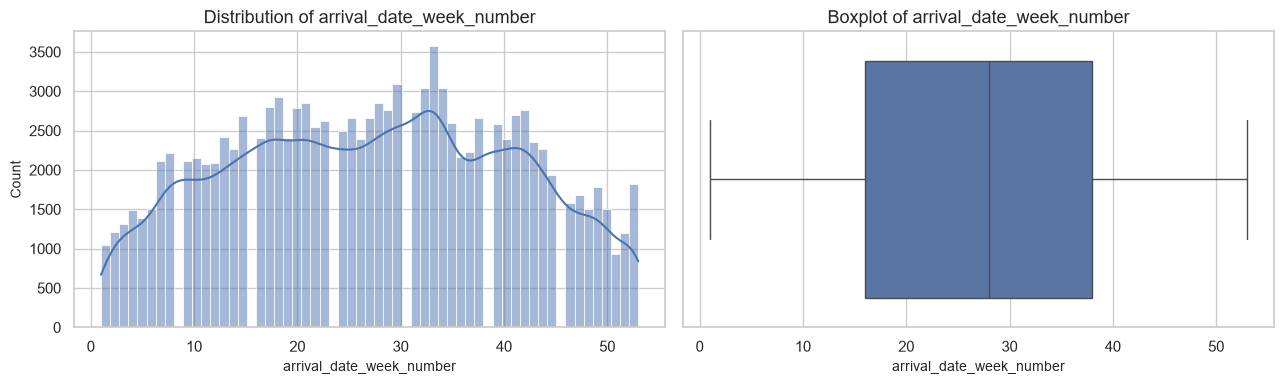


Column: arrival_date_day_of_month
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 31


,Summary
count,"119,390.00"
mean,15.80
std,8.78
min,1.00
25%,8.00
50%,16.00
75%,23.00
max,31.00


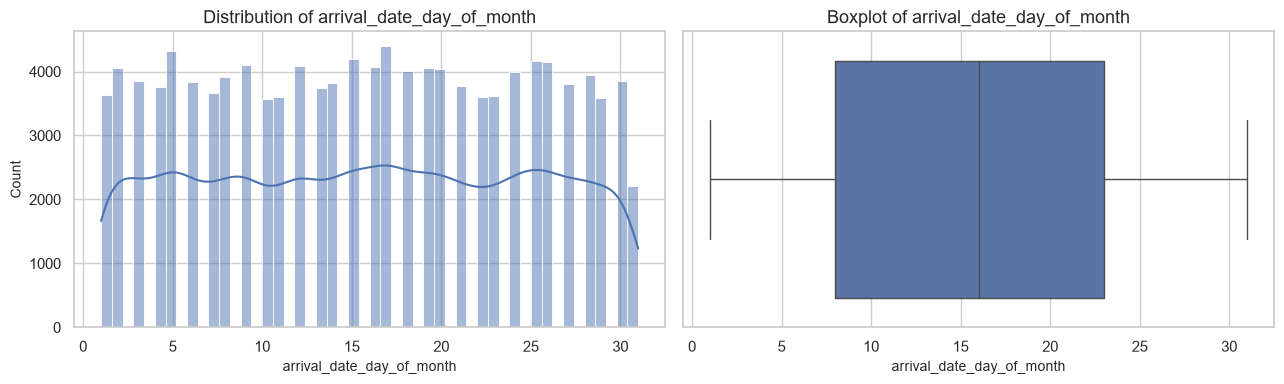


Column: stays_in_weekend_nights
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 17


,Summary
count,"119,390.00"
mean,0.93
std,1.00
min,0.00
25%,0.00
50%,1.00
75%,2.00
max,19.00


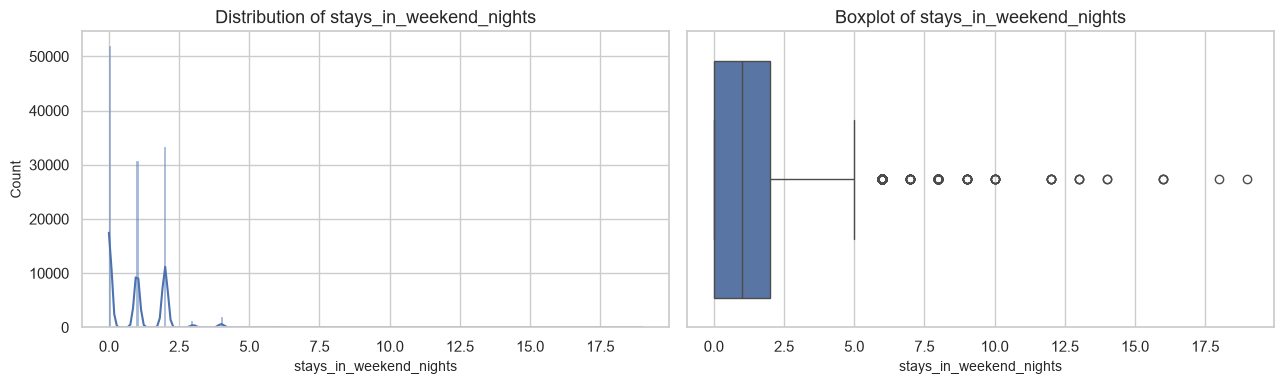


Column: stays_in_week_nights
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 35


,Summary
count,"119,390.00"
mean,2.50
std,1.91
min,0.00
25%,1.00
50%,2.00
75%,3.00
max,50.00


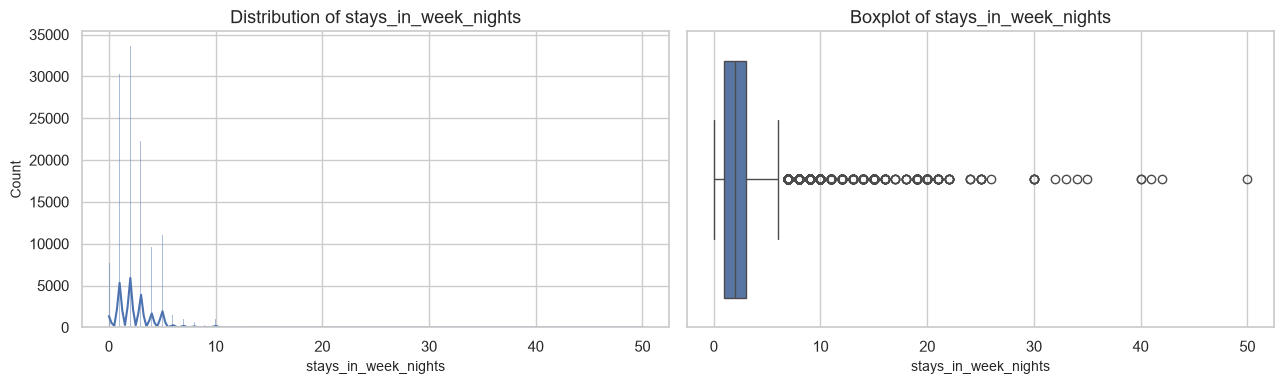


Column: adults
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 14


,Summary
count,"119,390.00"
mean,1.86
std,0.58
min,0.00
25%,2.00
50%,2.00
75%,2.00
max,55.00


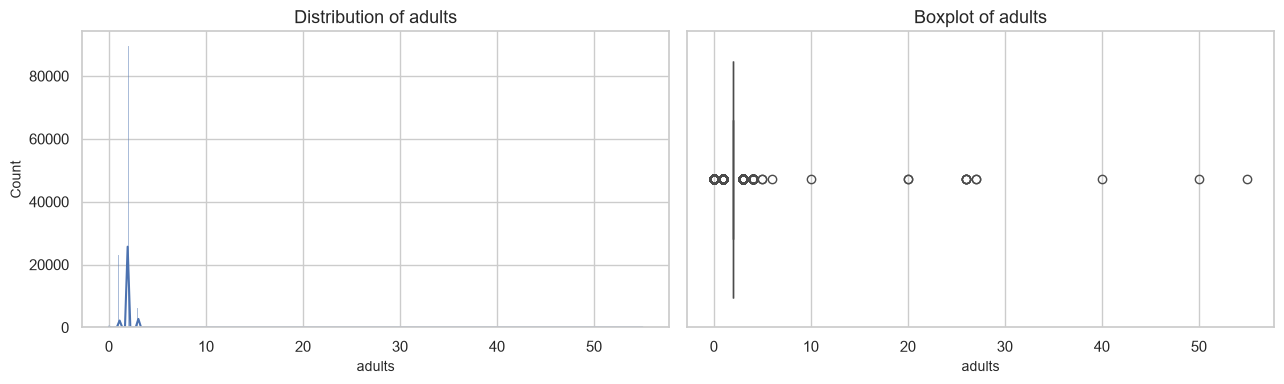


Column: children
Data type: float64
Missing values: 4
Missing percentage: 0.0
Unique values: 5


,Summary
count,"119,386.00"
mean,0.10
std,0.40
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,10.00


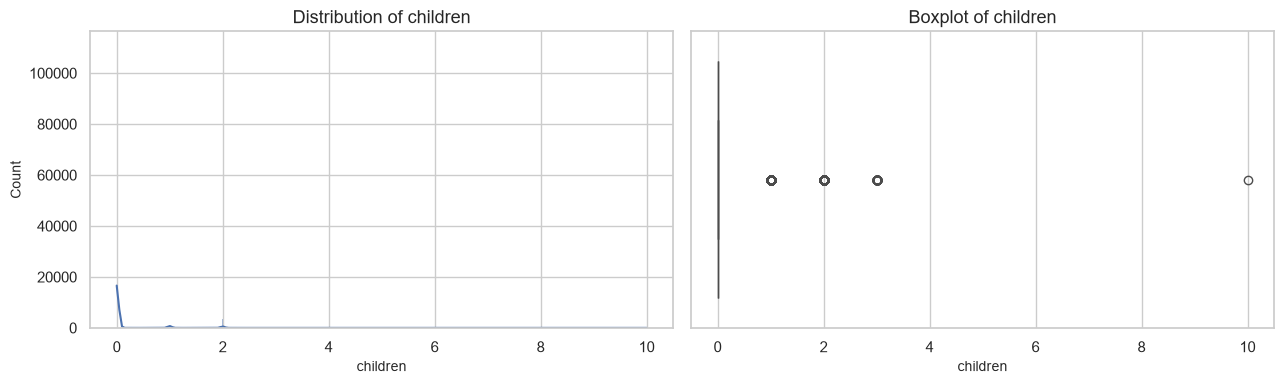


Column: babies
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 5


,Summary
count,"119,390.00"
mean,0.01
std,0.10
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,10.00


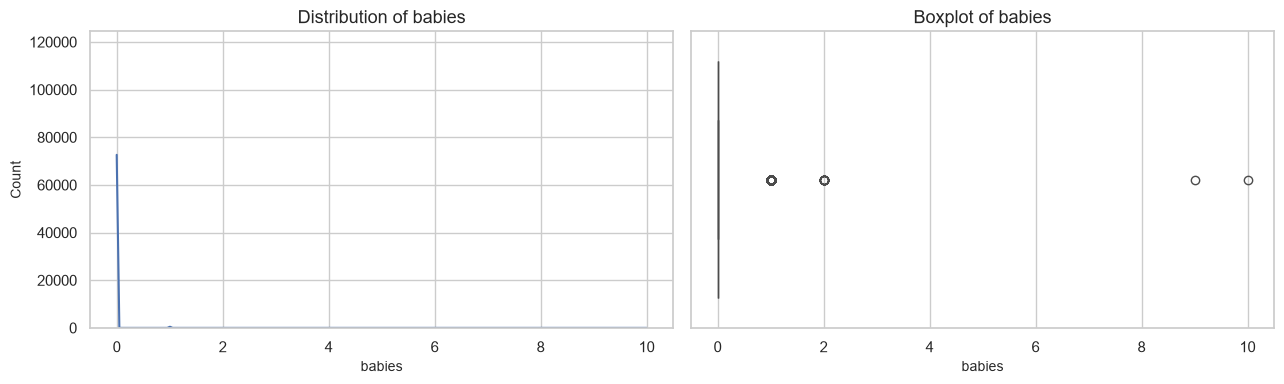


Column: meal
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 5


,Frequency
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798


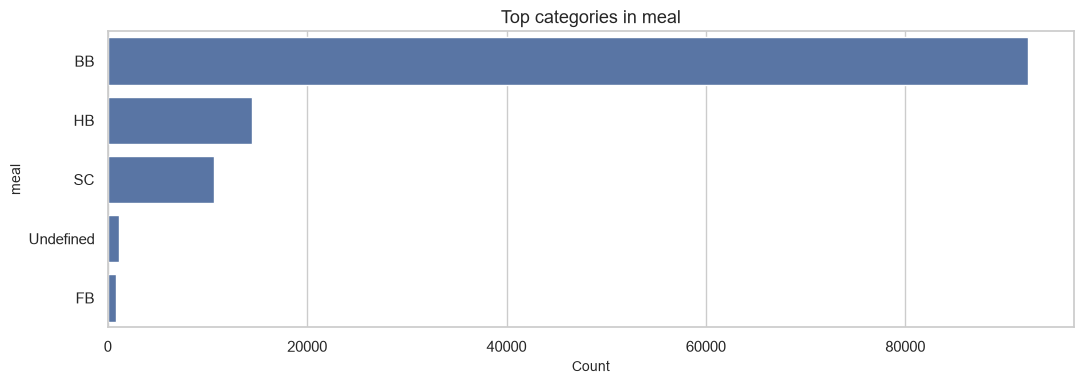


Column: country
Data type: str
Missing values: 488
Missing percentage: 0.41
Unique values: 177


,Frequency
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
ITA,3766
IRL,3375
BEL,2342
BRA,2224


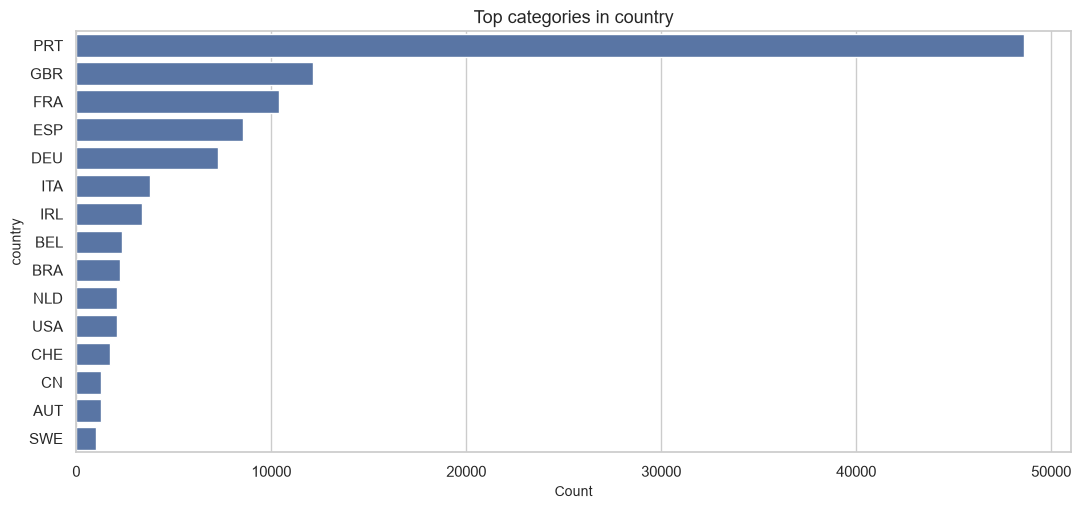


Column: market_segment
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 8


,Frequency
market_segment,
Online TA,56477
Offline TA/TO,24219
Groups,19811
Direct,12606
Corporate,5295
Complementary,743
Aviation,237
Undefined,2


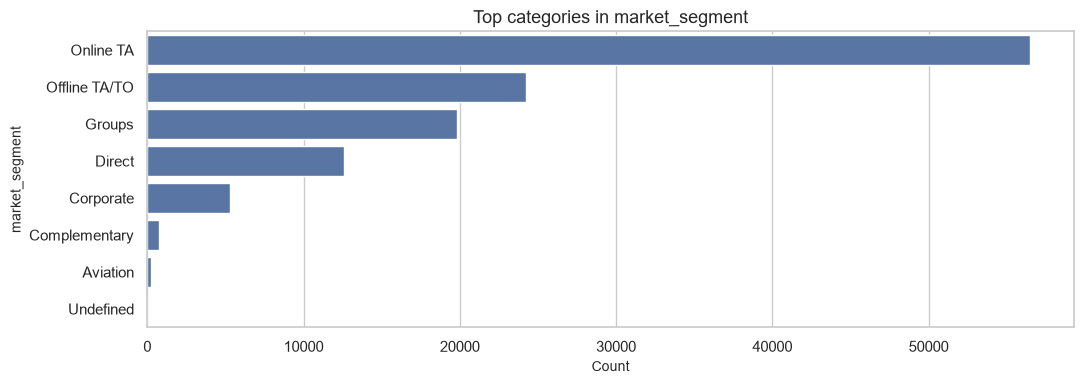


Column: distribution_channel
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 5


,Frequency
distribution_channel,
TA/TO,97870
Direct,14645
Corporate,6677
GDS,193
Undefined,5


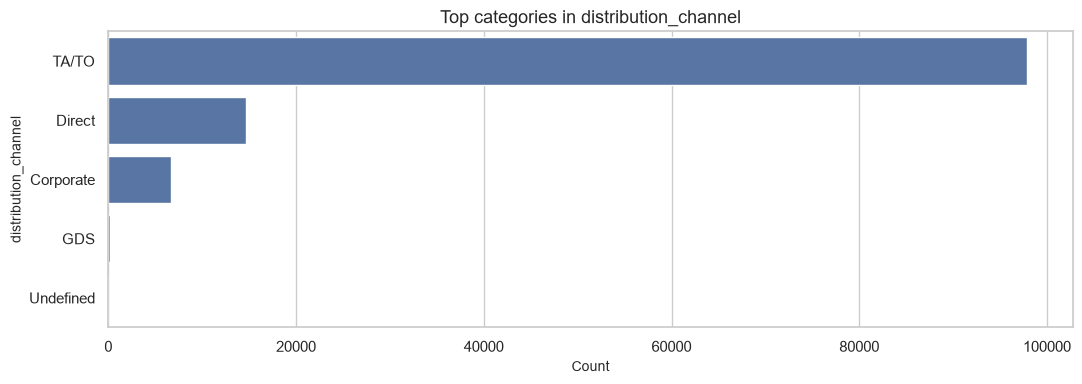


Column: is_repeated_guest
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 2


,Summary
count,"119,390.00"
mean,0.03
std,0.18
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,1.00


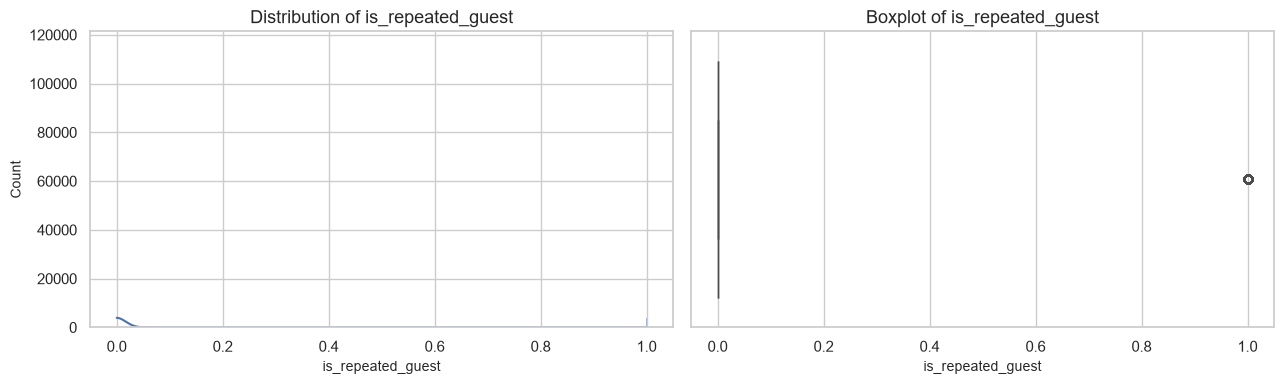


Column: previous_cancellations
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 15


,Summary
count,"119,390.00"
mean,0.09
std,0.84
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,26.00


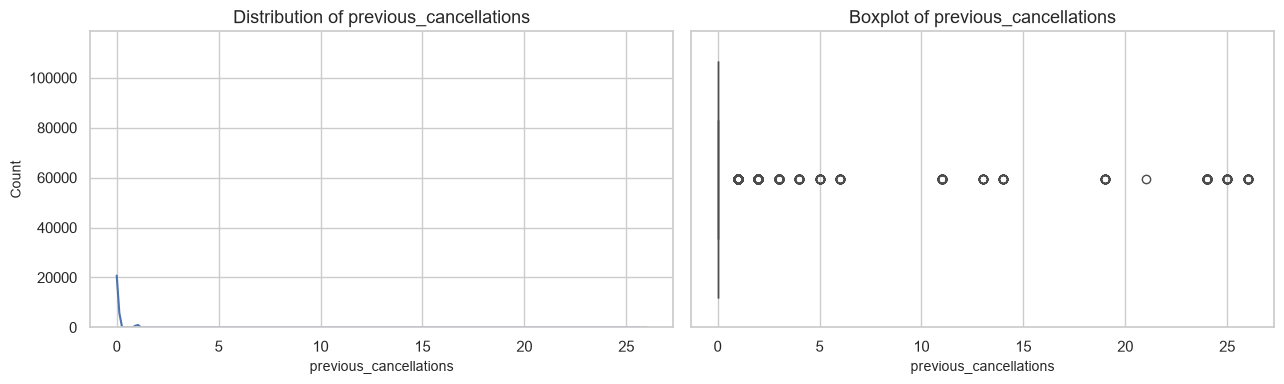


Column: previous_bookings_not_canceled
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 73


,Summary
count,"119,390.00"
mean,0.14
std,1.50
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,72.00


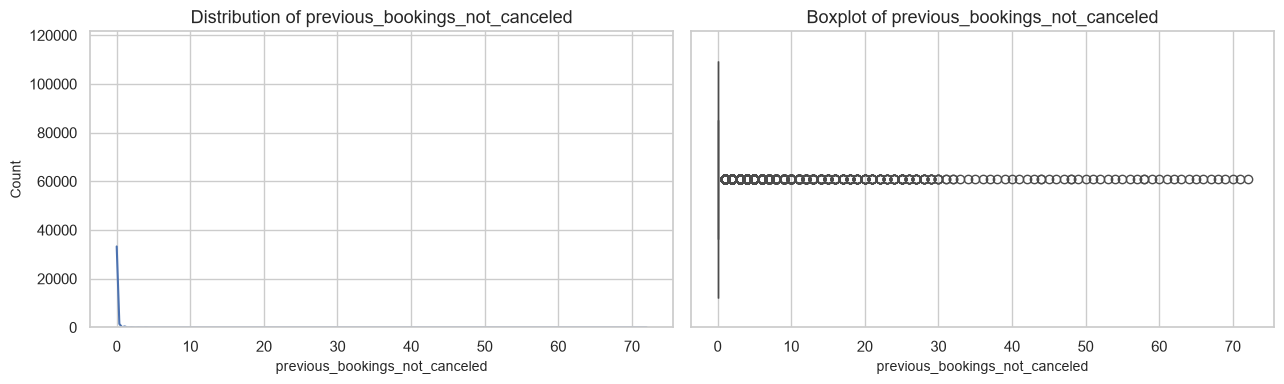


Column: reserved_room_type
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 10


,Frequency
reserved_room_type,
A,85994
D,19201
E,6535
F,2897
G,2094
B,1118
C,932
H,601
P,12


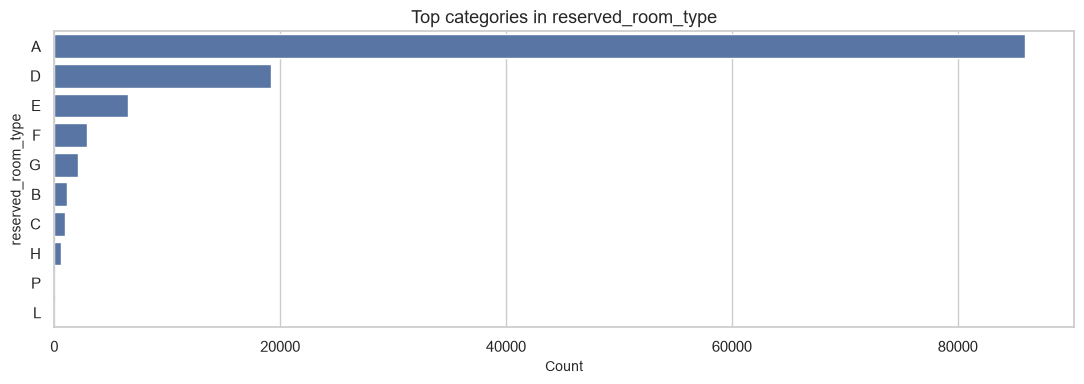


Column: assigned_room_type
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 12


,Frequency
assigned_room_type,
A,74053
D,25322
E,7806
F,3751
G,2553
C,2375
B,2163
H,712
I,363


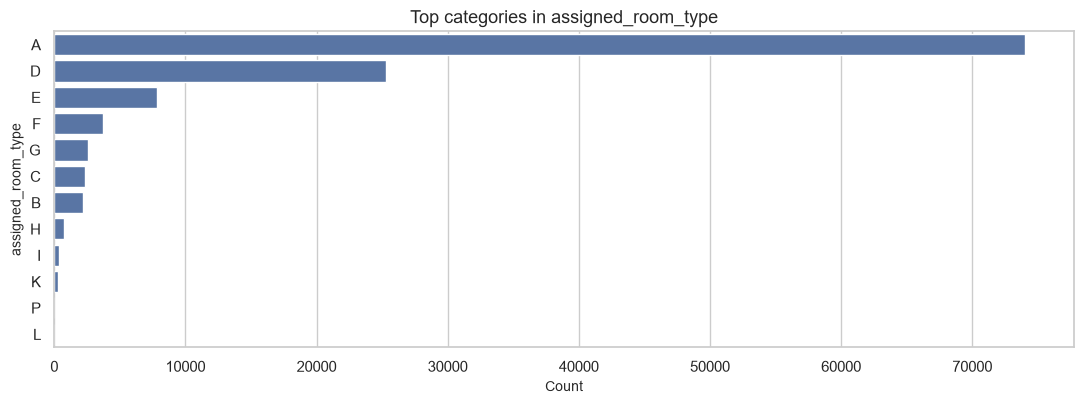


Column: booking_changes
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 21


,Summary
count,"119,390.00"
mean,0.22
std,0.65
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,21.00


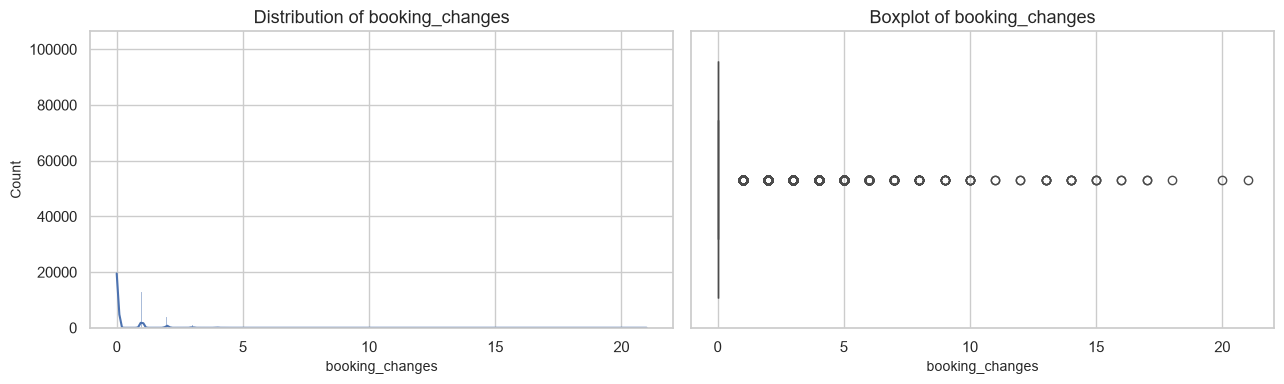


Column: deposit_type
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 3


,Frequency
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


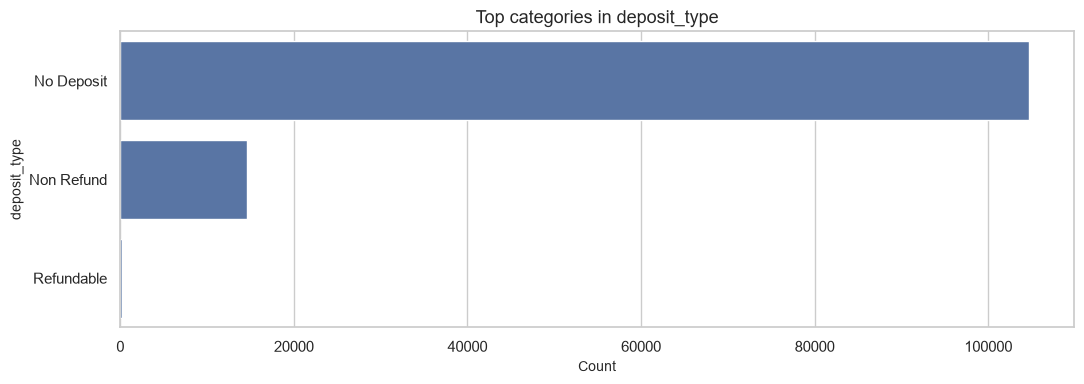


Column: agent
Data type: float64
Missing values: 16340
Missing percentage: 13.69
Unique values: 333


,Summary
count,"103,050.00"
mean,86.69
std,110.77
min,1.00
25%,9.00
50%,14.00
75%,229.00
max,535.00


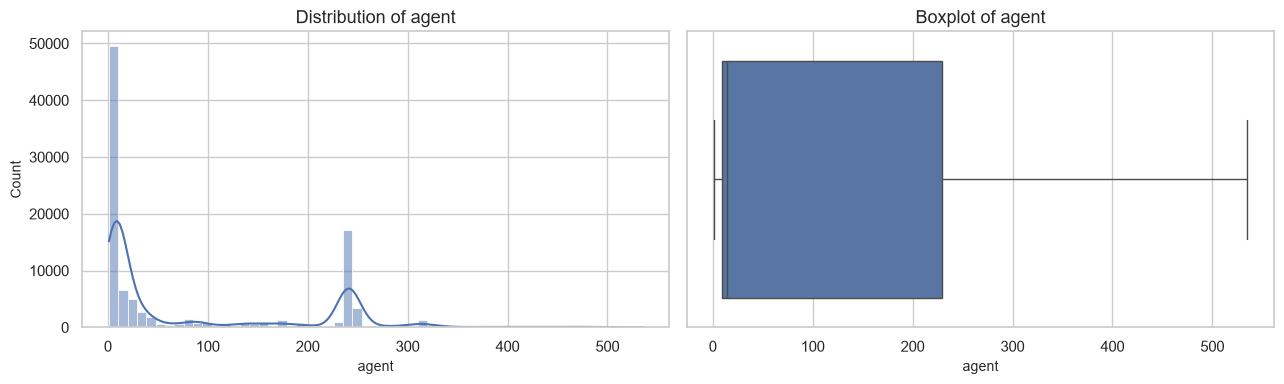


Column: company
Data type: float64
Missing values: 112593
Missing percentage: 94.31
Unique values: 352


,Summary
count,"6,797.00"
mean,189.27
std,131.66
min,6.00
25%,62.00
50%,179.00
75%,270.00
max,543.00


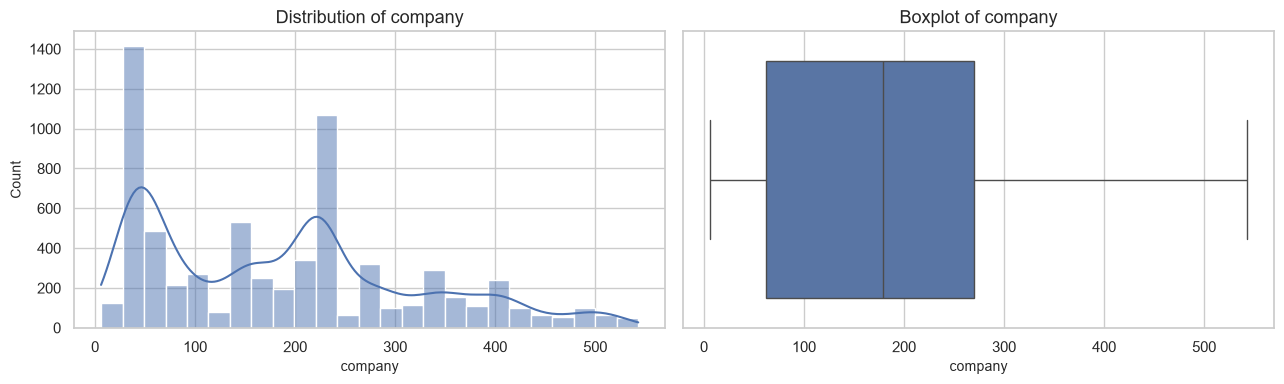


Column: days_in_waiting_list
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 128


,Summary
count,"119,390.00"
mean,2.32
std,17.59
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,391.00


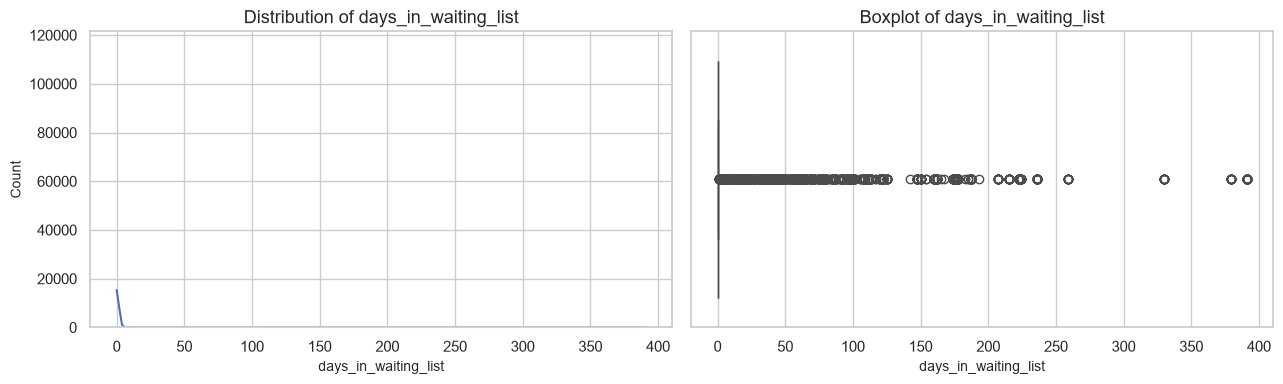


Column: customer_type
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 4


,Frequency
customer_type,
Transient,89613
Transient-Party,25124
Contract,4076
Group,577


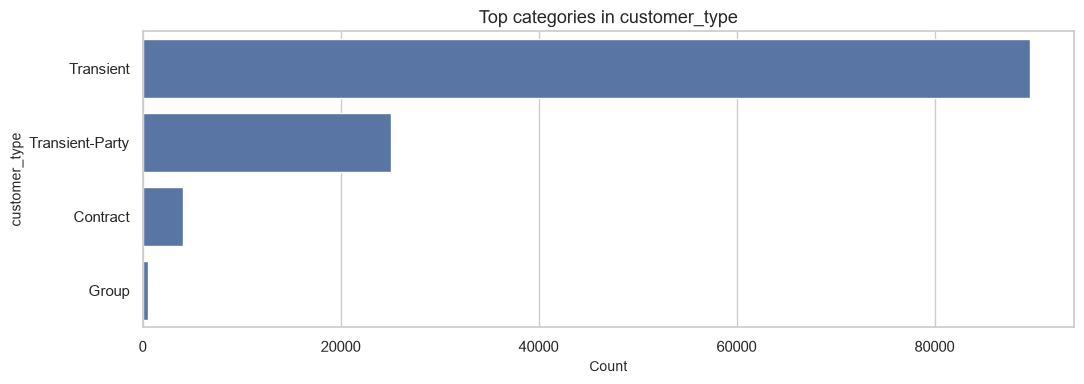


Column: adr
Data type: float64
Missing values: 0
Missing percentage: 0.0
Unique values: 8879


,Summary
count,"119,390.00"
mean,101.83
std,50.54
min,-6.38
25%,69.29
50%,94.58
75%,126.00
max,"5,400.00"


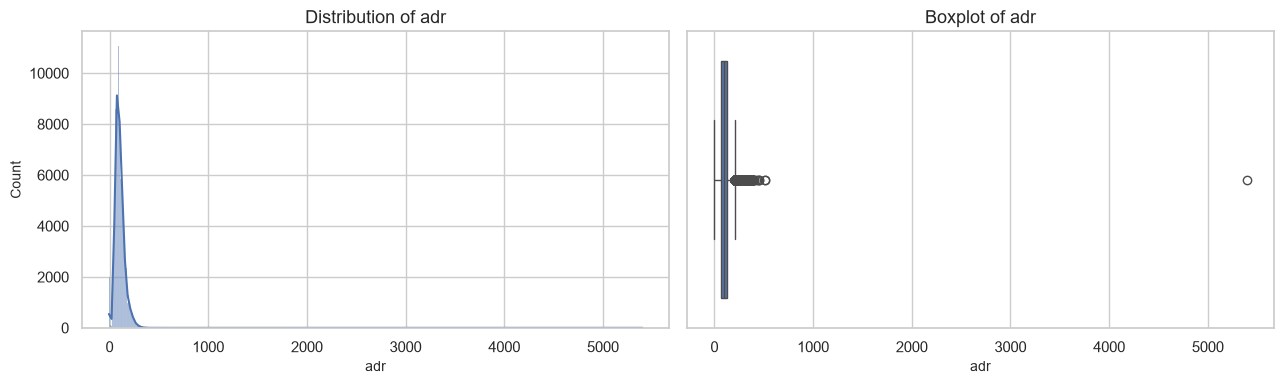


Column: required_car_parking_spaces
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 5


,Summary
count,"119,390.00"
mean,0.06
std,0.25
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,8.00


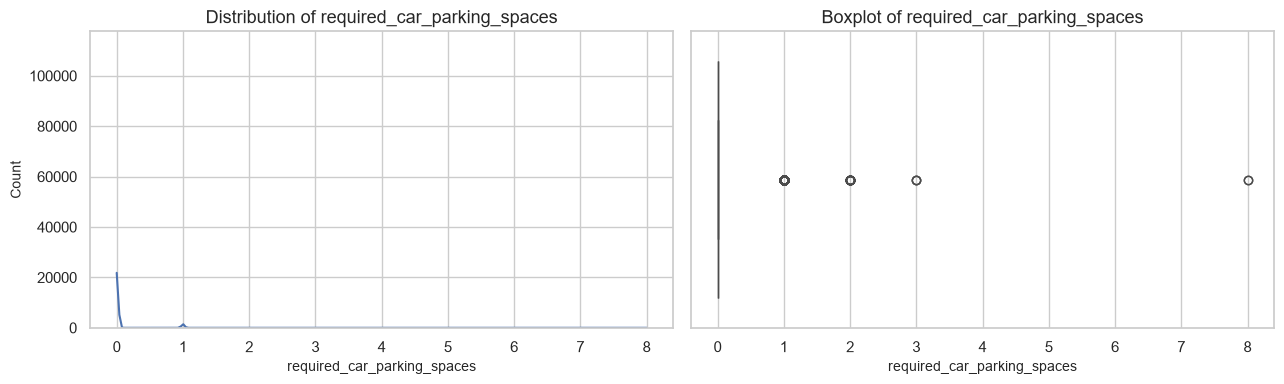


Column: total_of_special_requests
Data type: int64
Missing values: 0
Missing percentage: 0.0
Unique values: 6


,Summary
count,"119,390.00"
mean,0.57
std,0.79
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,5.00


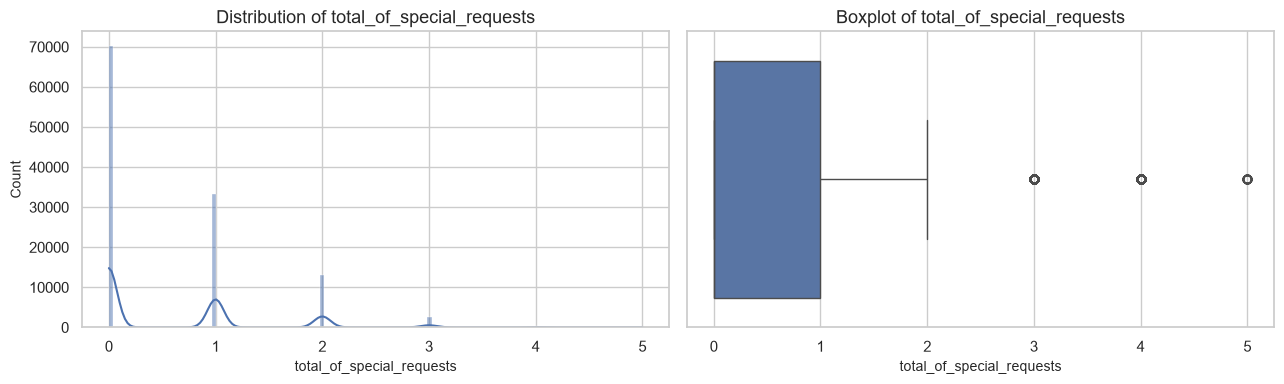


Column: reservation_status
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 3


,Frequency
reservation_status,
Check-Out,75166
Canceled,43017
No-Show,1207


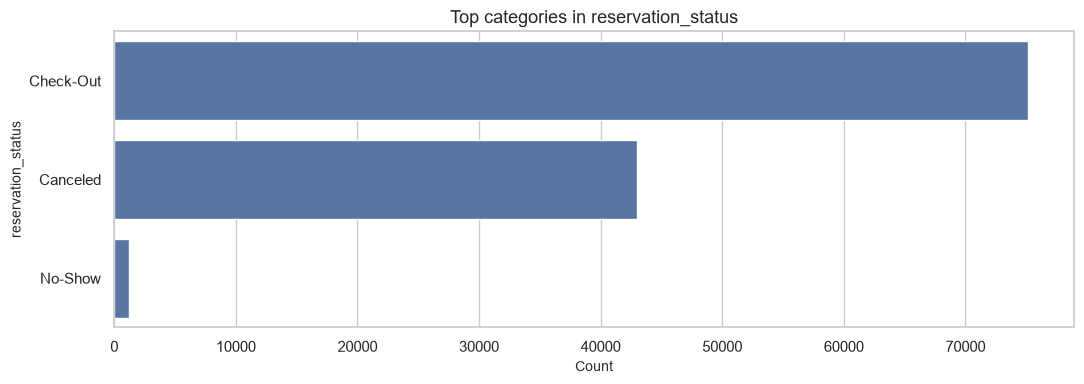


Column: reservation_status_date
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 926


,Frequency
reservation_status_date,
2015-10-21,1461
2015-07-06,805
2016-11-25,790
2015-01-01,763
2016-01-18,625
2015-07-02,469
2016-12-07,450
2015-12-18,423
2016-02-09,412


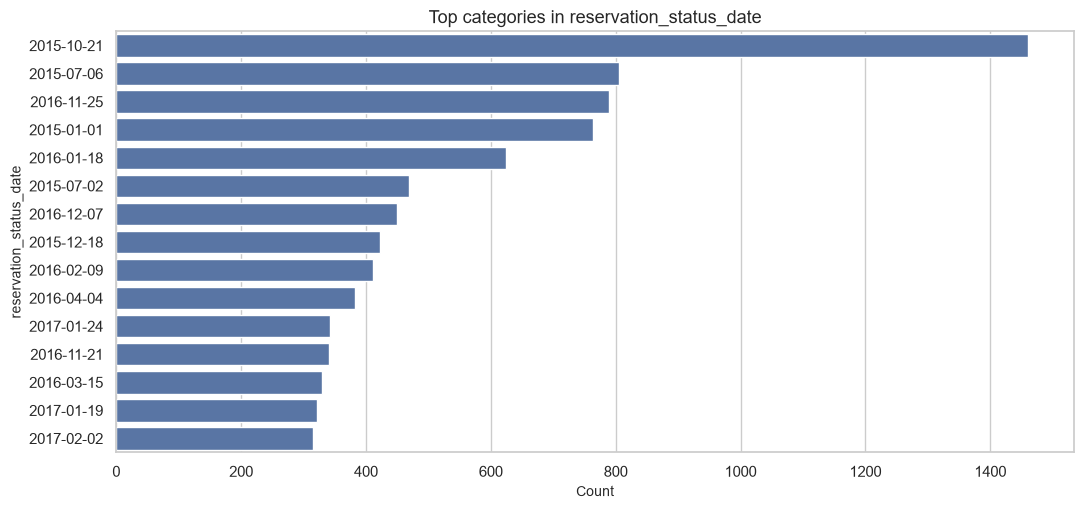


Column: name
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 81503
Identifier field: individual values are not displayed.


,Measure,Count
0,Missing values,0
1,Unique values,81503
2,Present values,119390



Column: email
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 115889
Identifier field: individual values are not displayed.


,Measure,Count
0,Missing values,0
1,Unique values,115889
2,Present values,119390



Column: phone-number
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 119390
Identifier field: individual values are not displayed.


,Measure,Count
0,Missing values,0
1,Unique values,119390
2,Present values,119390



Column: credit_card
Data type: str
Missing values: 0
Missing percentage: 0.0
Unique values: 9000
Identifier field: individual values are not displayed.


,Measure,Count
0,Missing values,0
1,Unique values,9000
2,Present values,119390


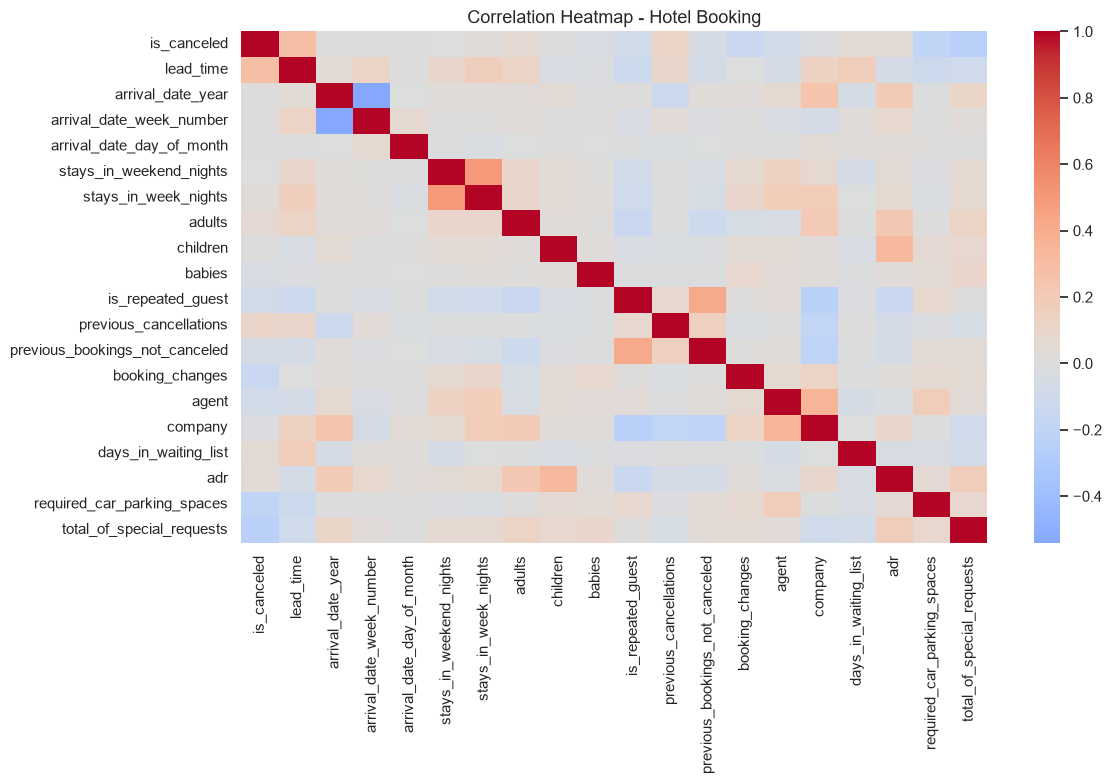

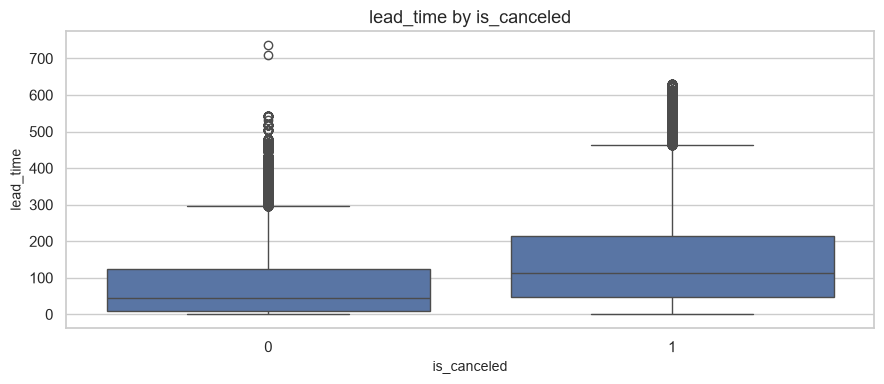

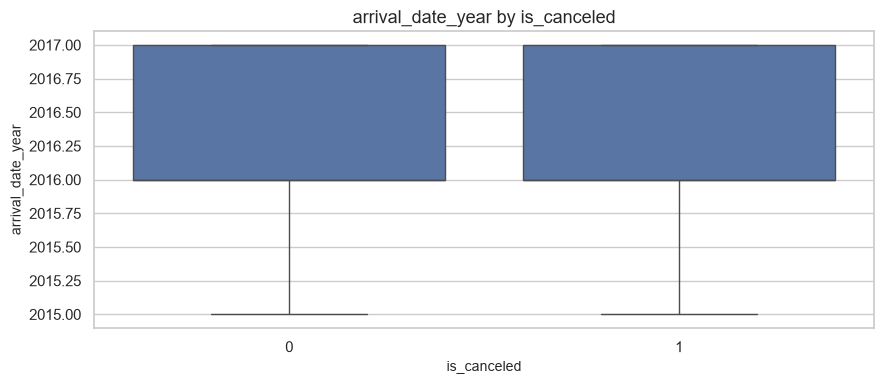

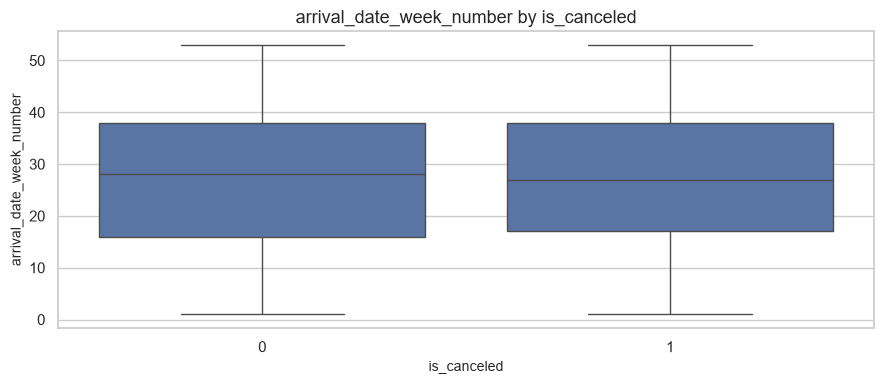

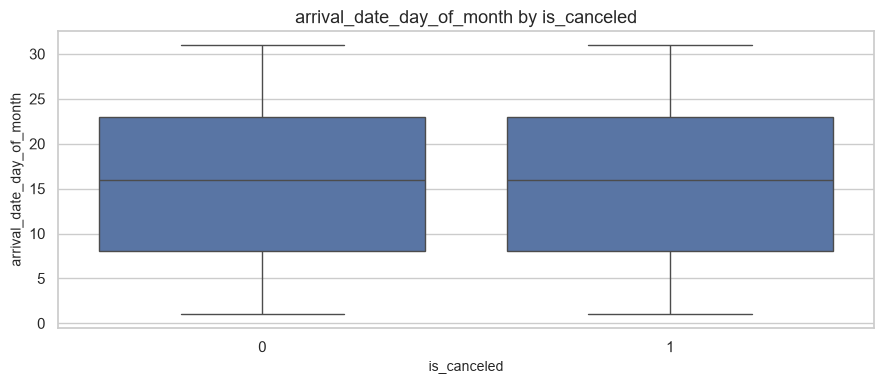

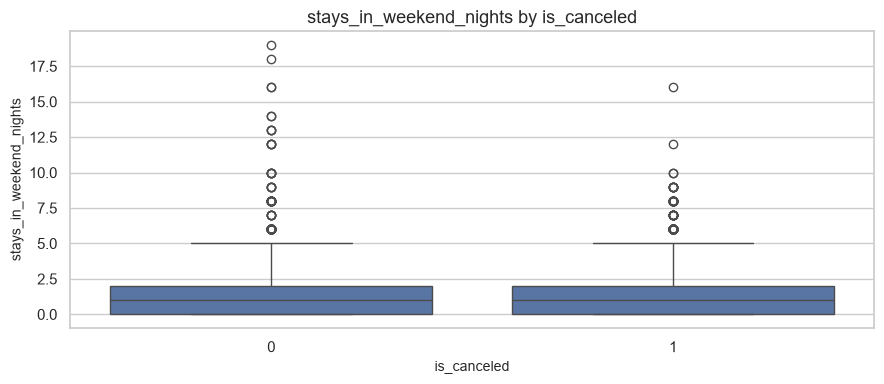

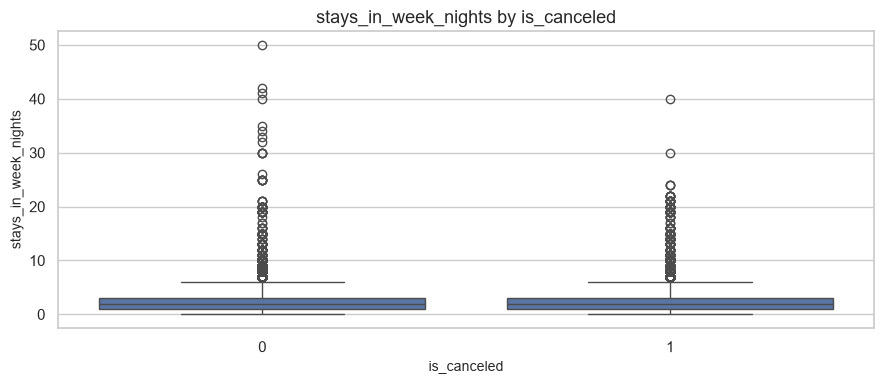

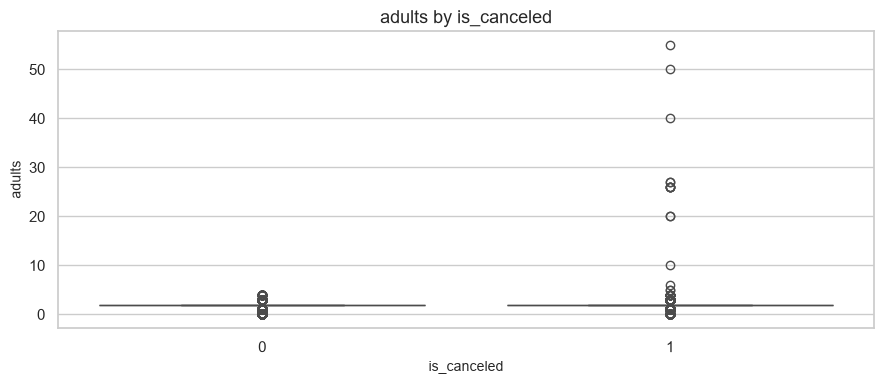

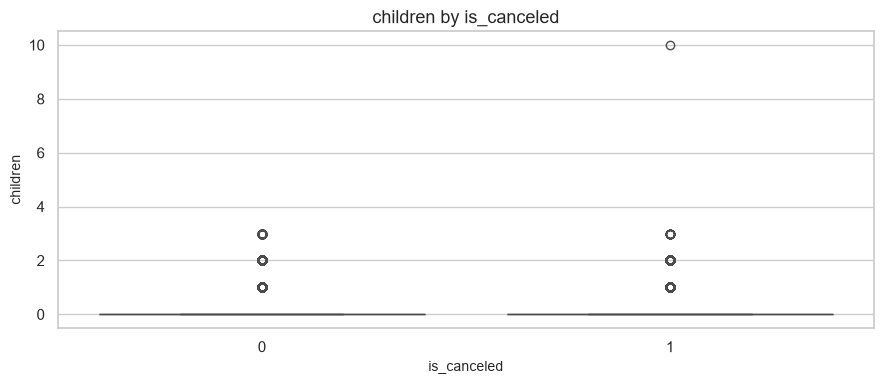

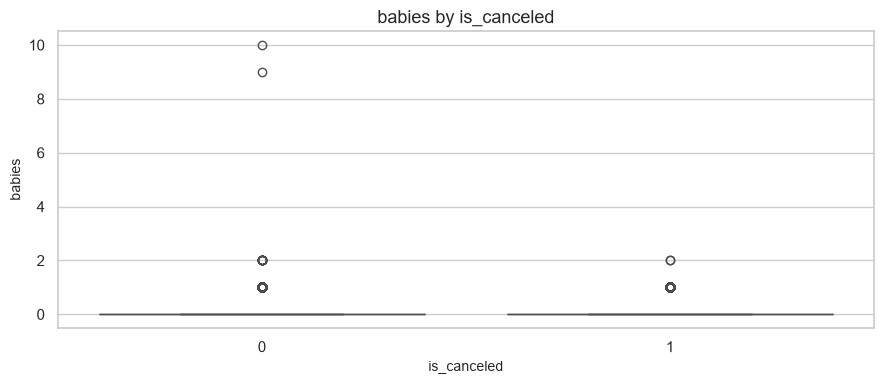

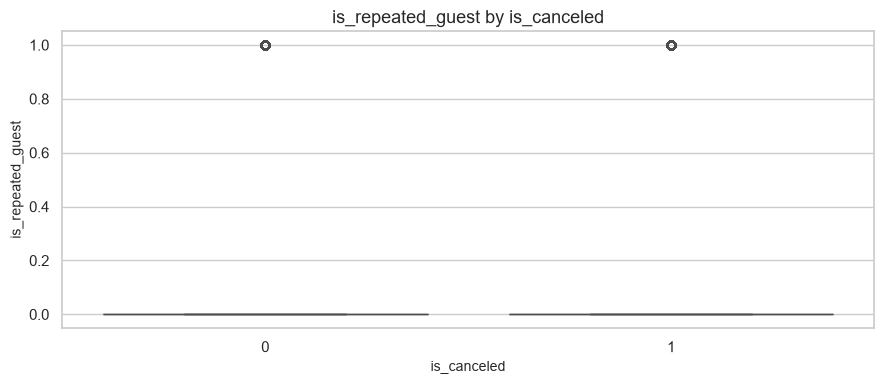

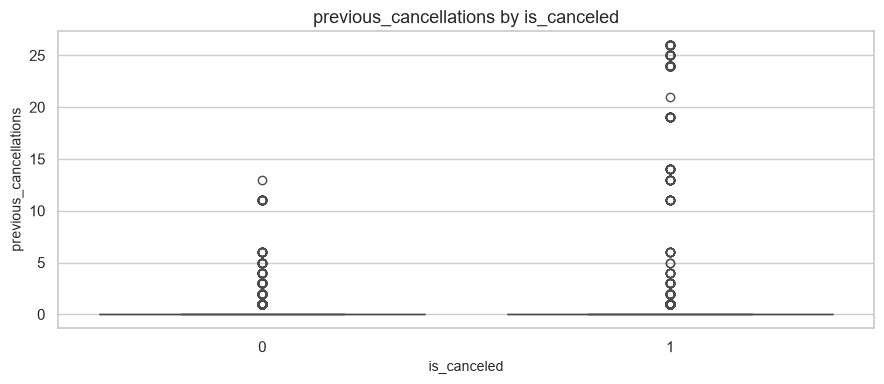

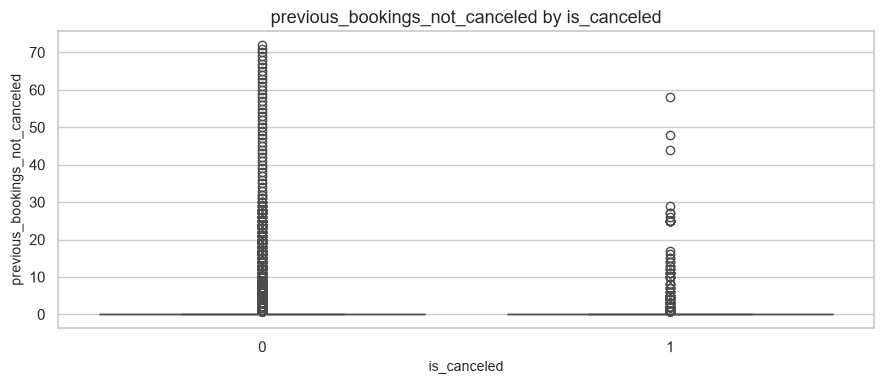

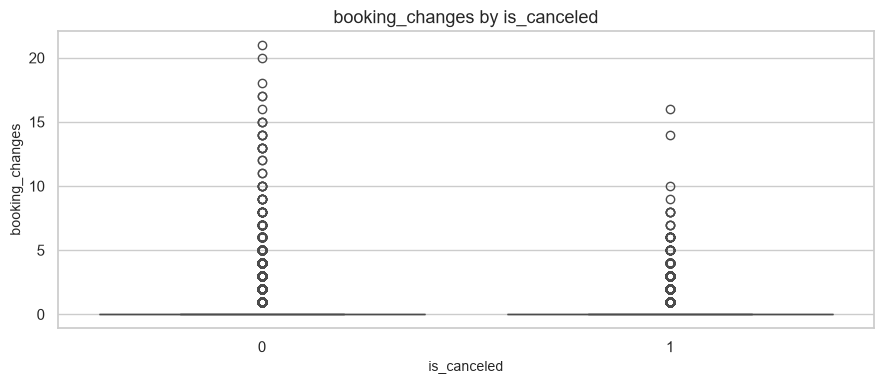

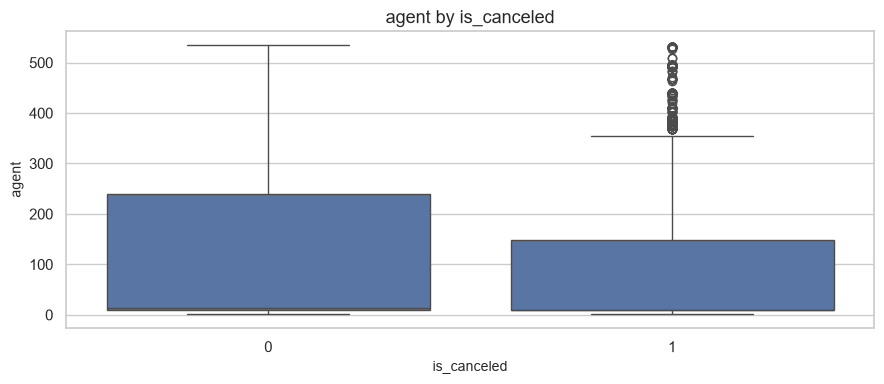

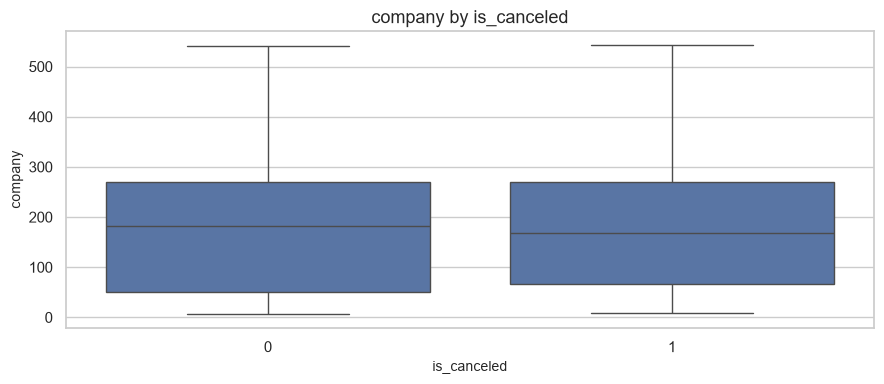

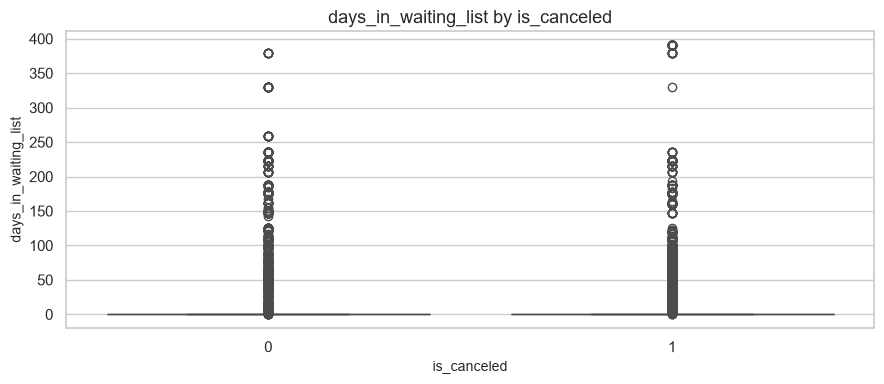

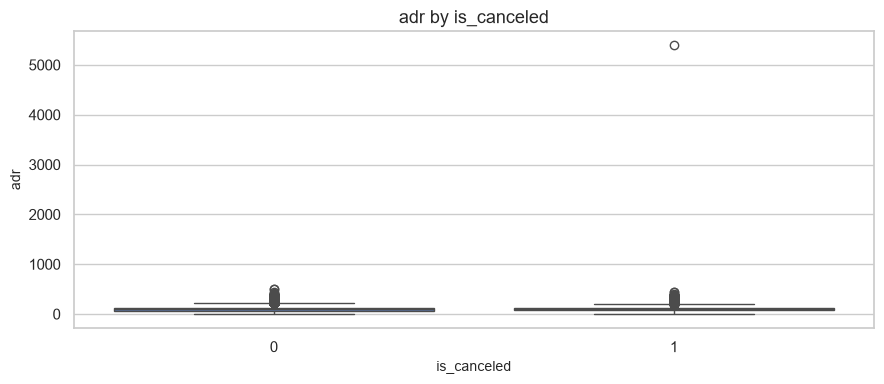

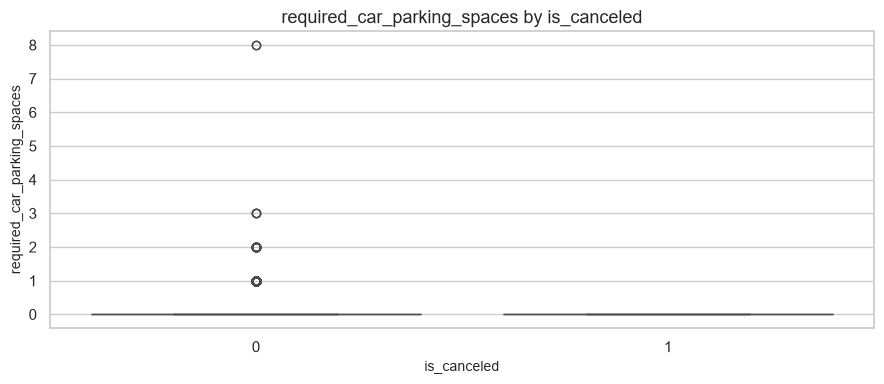

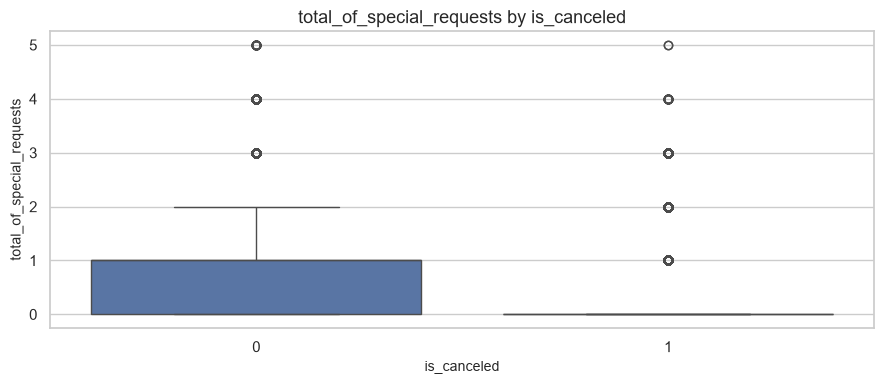

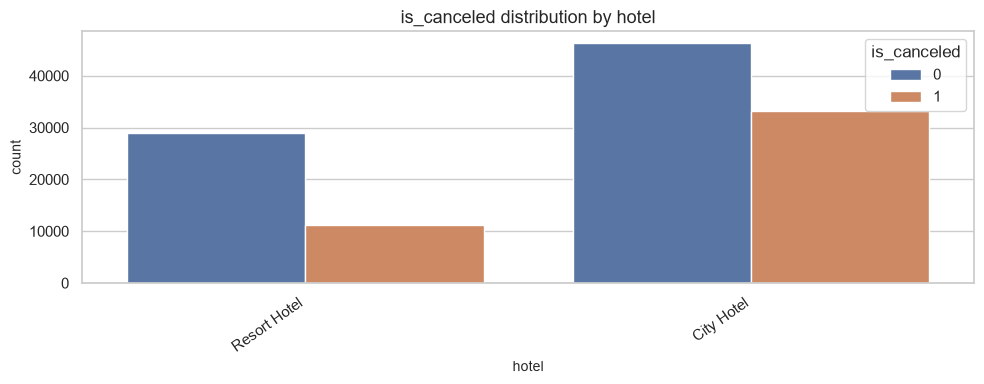

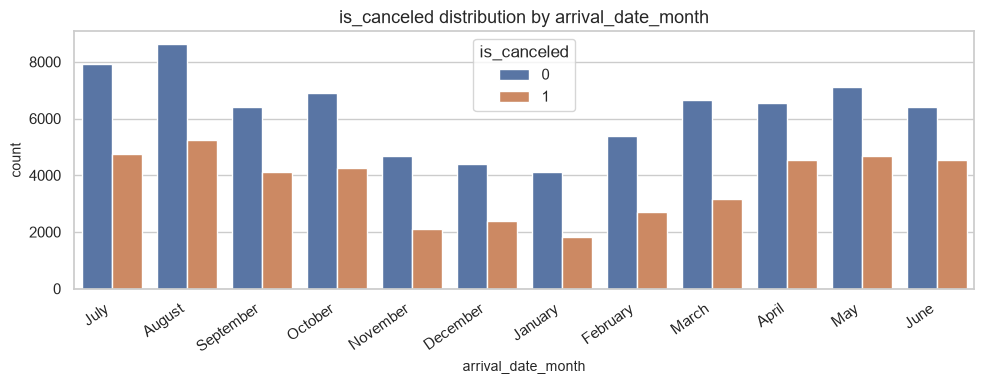

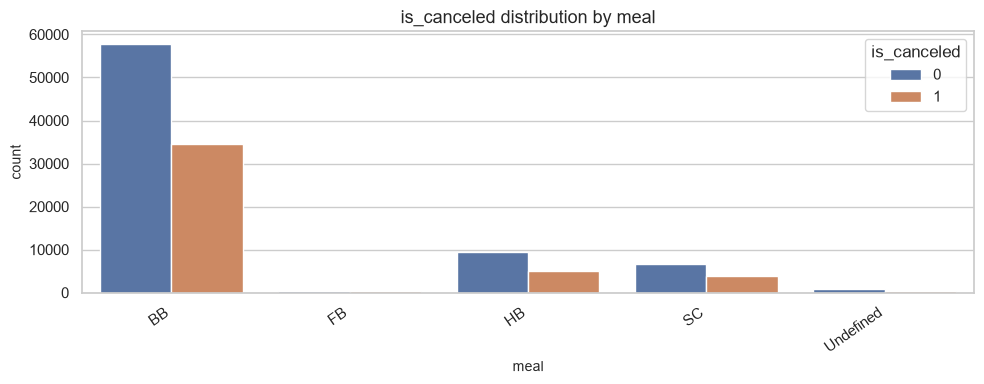

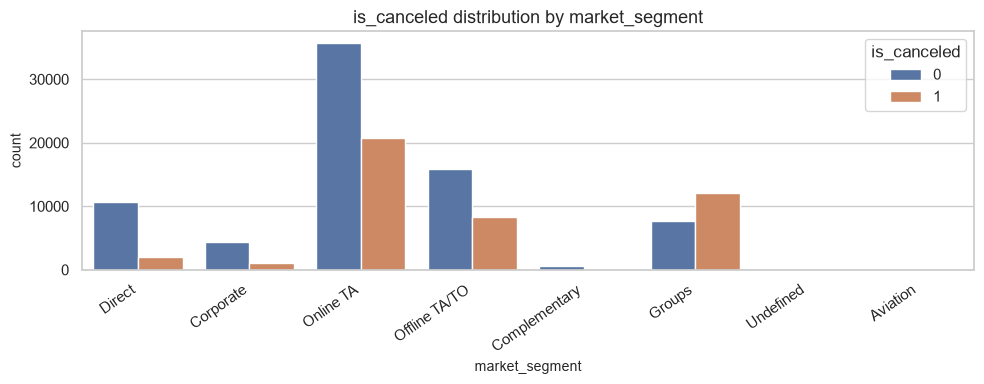

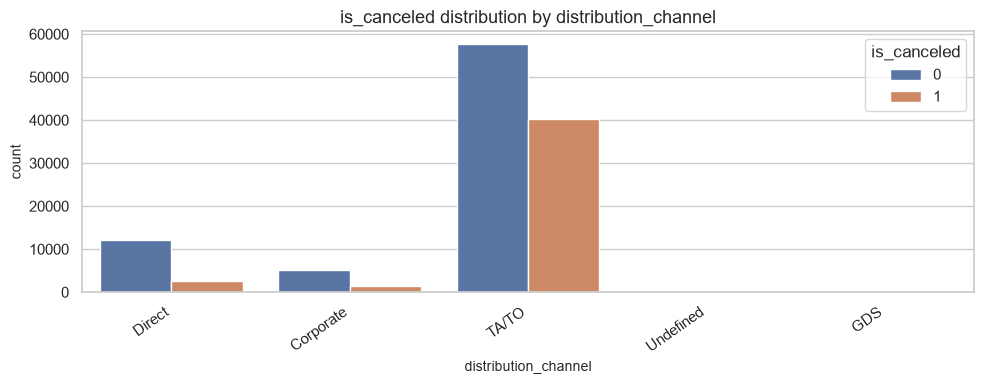

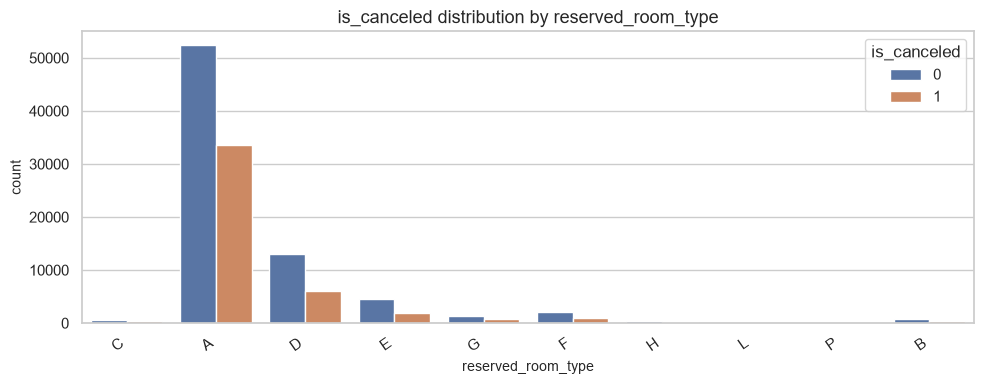

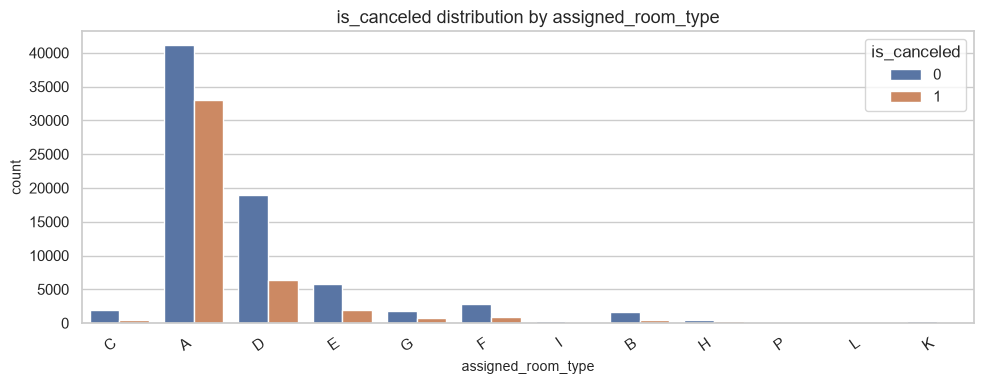

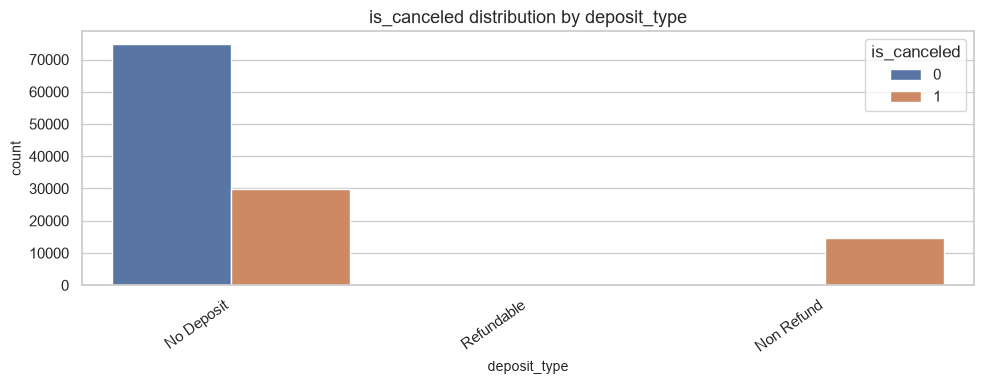

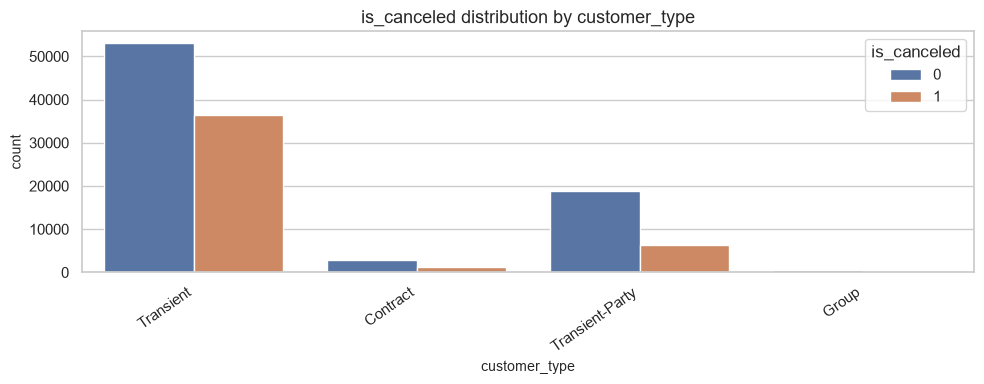

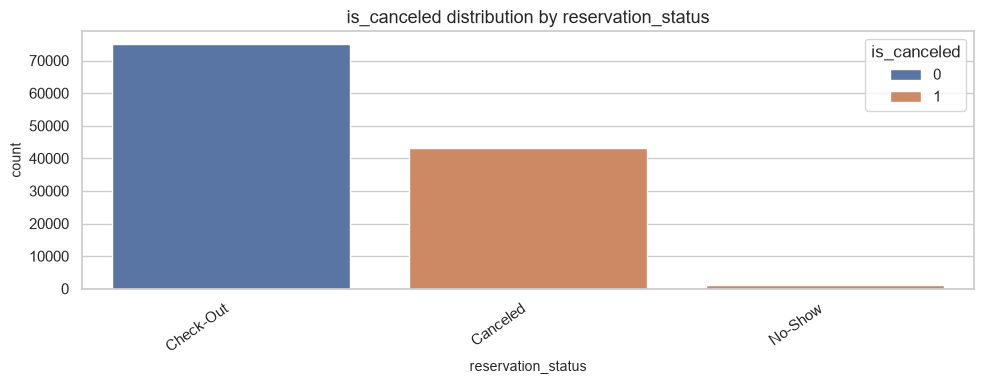

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,is_canceled,-1.50,2.50,0,0.00
1,lead_time,-195.00,373.00,3005,2.52
2,arrival_date_year,"2,014.50","2,018.50",0,0.00
3,arrival_date_week_number,-17.00,71.00,0,0.00
4,arrival_date_day_of_month,-14.50,45.50,0,0.00
5,stays_in_weekend_nights,-3.00,5.00,265,0.22
6,stays_in_week_nights,-2.00,6.00,3354,2.81
7,adults,2.00,2.00,29710,24.88
8,children,0.00,0.00,8590,7.20
9,babies,0.00,0.00,917,0.77


Cleaning summary: Hotel Booking
Duplicate rows removed: 0
Identifier columns excluded: ['name', 'email', 'phone-number', 'credit_card']
Remaining missing values: 0
Final shape: (119390, 32)

Missing values after cleaning:


,Missing Values
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0



Data types after cleaning:


,Data Type
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


Hotel dataset final verification
Shape: (119390, 32)
Missing values: 0
Duplicate rows: 32013


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,14.00,179.00,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,14.00,179.00,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,14.00,179.00,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,179.00,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,179.00,0,Transient,98.00,0,1,Check-Out,2015-07-03


In [5]:
hotel_raw = load_dataset(["hotel_booking.csv", "hotel_bookings.csv"])
hotel_report = inspect_dataset(hotel_raw, "Hotel Booking")
hotel_identifiers = ["name", "email", "phone-number", "credit_card"]
analyze_columns(
    hotel_raw,
    "Hotel Booking",
    identifier_columns=hotel_identifiers
)
analyze_relationships(
    hotel_raw,
    "Hotel Booking",
    target_column="is_canceled"
)
hotel_outliers = outlier_summary(hotel_raw)
hotel_cleaned = clean_dataset(
    hotel_raw,
    "Hotel Booking",
    date_columns=["reservation_status_date"],
    identifier_columns=hotel_identifiers
)
print("Hotel dataset final verification")
print("Shape:", hotel_cleaned.shape)
print("Missing values:", hotel_cleaned.isna().sum().sum())
print("Duplicate rows:", hotel_cleaned.duplicated().sum())
display(hotel_cleaned.head())


### Hotel Booking: observations

Examine cancellation rates in relation to lead time, hotel type, deposit type, customer type, market segment, previous cancellations and special requests. Review the distributions of stay duration and average daily rate. The reservation status and reservation status date should be interpreted together because the status records the final outcome of the reservation.

The columns `name`, `email`, `phone-number` and `credit_card` contain direct personal identifiers. They are inspected through aggregate completeness and uniqueness information, not displayed as individual values, and are excluded from the cleaned analytical table.


# Final comparison and conclusion

The following cell compares the original and cleaned dataset sizes and summarizes the remaining missing values. Use the outputs from the preceding sections to write dataset-specific findings based on the actual values and plots.


In [6]:
final_summary = pd.DataFrame({
    "Dataset": ["Loan Eligibility", "Adult Census Income", "Hotel Booking"],
    "Original Rows": [len(loan_raw), len(adult_raw), len(hotel_raw)],
    "Original Columns": [loan_raw.shape[1], adult_raw.shape[1], hotel_raw.shape[1]],
    "Cleaned Rows": [len(loan_cleaned), len(adult_cleaned), len(hotel_cleaned)],
    "Cleaned Columns": [loan_cleaned.shape[1], adult_cleaned.shape[1], hotel_cleaned.shape[1]],
    "Missing Values After Cleaning": [
        int(loan_cleaned.isna().sum().sum()),
        int(adult_cleaned.isna().sum().sum()),
        int(hotel_cleaned.isna().sum().sum())
    ],
    "Duplicate Rows After Cleaning": [
        int(loan_cleaned.duplicated().sum()),
        int(adult_cleaned.duplicated().sum()),
        int(hotel_cleaned.duplicated().sum())
    ]
})

display(final_summary)

print("All three datasets have been loaded, analyzed and cleaned.")
print("Review the column-level outputs and plots before submitting the notebook.")


,Dataset,Original Rows,Original Columns,Cleaned Rows,Cleaned Columns,Missing Values After Cleaning,Duplicate Rows After Cleaning
0,Loan Eligibility,1614,13,1614,12,0,0
1,Adult Census Income,48842,15,48790,15,0,1
2,Hotel Booking,119390,36,119390,32,0,32013


All three datasets have been loaded, analyzed and cleaned.
Review the column-level outputs and plots before submitting the notebook.
